In [ ]:
# Install required libraries (Colab-friendly)
!pip install pmdarima --quiet
!pip install PyWavelets --quiet

# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Stats / time series
from scipy import stats
from scipy.stats import gamma, norm, kruskal
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
import pmdarima as pm
import pywt

# ML
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              mean_absolute_error, mean_squared_error, r2_score)

# DL
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Bidirectional, Conv1D, MaxPooling1D, Dense, Flatten, Dropout

# Display settings
pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (10, 5)

print("✅ Environment ready")
print("TensorFlow version:", tf.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 23.0 MB/s eta 0:00:00
✅ Environment ready
TensorFlow version: 2.20.0


In [ ]:
from google.colab import files

# Upload the CSV file (Climate_Data_Set_-_Sheet1.csv)
uploaded = files.upload()

# Load into pandas
filename = list(uploaded.keys())[0]
df_raw = pd.read_csv(filename)

# Drop any empty/unnamed trailing columns (artifact from Excel export)
df_raw = df_raw.loc[:, ~df_raw.columns.str.contains('^Unnamed')]

print("Shape:", df_raw.shape)
print("\nColumns:", df_raw.columns.tolist())
print("\nStations:", df_raw['Location'].unique())
print("\nDate range:", df_raw['Date'].min(), "to", df_raw['Date'].max())

df_raw.head(10)

Saving Climate Data Set - Sheet1.csv to Climate Data Set - Sheet1 (1).csv
Shape: (1872, 9)

Columns: ['Date', 'Location', 'Rainfall (mm)', 'Max temp (°C)', 'Min temp (°C)', 'Wind speed (m/s)', 'Sunshine (Hours)', 'Humidity (%)', 'Cloud coverage (Octs)']

Stations: ['Rajshahi' 'Ishwardi' 'Bogura' 'Syedpur' 'Rangpur' 'Dinajpur']

Date range: 1998-01 to 2023-12


,Date,Location,Rainfall (mm),Max temp (°C),Min temp (°C),Wind speed (m/s),Sunshine (Hours),Humidity (%),Cloud coverage (Octs)
0,1998-01,Rajshahi,16,21.28,10.35,0.53,5.26,84.29,2.81
1,1998-02,Rajshahi,5,27.55,13.91,0.60,7.27,75.18,2.21
2,1998-03,Rajshahi,52,30.71,16.20,0.85,8.49,69.00,2.77
3,1998-04,Rajshahi,33,33.98,22.12,1.15,8.27,74.00,3.33
4,1998-05,Rajshahi,129,34.93,24.90,1.56,8.28,75.84,4.94
5,1998-06,Rajshahi,92,35.73,27.48,1.54,5.87,81.57,5.17
6,1998-07,Rajshahi,404,32.85,26.53,1.37,3.95,90.03,6.68
7,1998-08,Rajshahi,268,32.84,26.79,1.18,4.29,88.87,6.68
8,1998-09,Rajshahi,310,32.63,26.18,1.02,5.96,88.03,5.07
9,1998-10,Rajshahi,198,32.61,24.97,0.50,6.62,86.42,3.97


**Fix Data Types & Parse Dates**

In [ ]:
df = df_raw.copy()

# Fix comma-formatted numbers in Rainfall (e.g., "1,035" -> 1035)
df['Rainfall (mm)'] = df['Rainfall (mm)'].astype(str).str.replace(',', '', regex=False)
df['Rainfall (mm)'] = pd.to_numeric(df['Rainfall (mm)'], errors='coerce')

# Ensure all weather columns are numeric
numeric_cols = ['Rainfall (mm)', 'Max temp (°C)', 'Min temp (°C)', 'Wind speed (m/s)',
                 'Sunshine (Hours)', 'Humidity (%)', 'Cloud coverage (Octs)']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Parse Date (format: YYYY-MM) into proper datetime
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m')
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

# Sort by station then date
df = df.sort_values(['Location', 'Date']).reset_index(drop=True)

print("Data types after fix:")
print(df.dtypes)
print("\nMissing values per column:")
print(df[numeric_cols].isna().sum())

Data types after fix:
Date                     datetime64[ns]
Location                         object
Rainfall (mm)                   float64
Max temp (°C)                   float64
Min temp (°C)                   float64
Wind speed (m/s)                float64
Sunshine (Hours)                float64
Humidity (%)                    float64
Cloud coverage (Octs)           float64
Year                              int32
Month                             int32
dtype: object

Missing values per column:
Rainfall (mm)            60
Max temp (°C)             0
Min temp (°C)             0
Wind speed (m/s)         24
Sunshine (Hours)         62
Humidity (%)              0
Cloud coverage (Octs)    15
dtype: int64


**Missing Value Imputation (Station-Specific Monthly Climatology)**

In [ ]:
def impute_monthly_climatology(data, cols):
    data = data.copy()
    for col in cols:
        # Compute mean for each (Location, Month) group, ignoring NaNs
        clim = data.groupby(['Location', 'Month'])[col].transform('mean')
        data[col] = data[col].fillna(clim)
    return data

df_clean = impute_monthly_climatology(df, numeric_cols)

print("Missing values AFTER imputation:")
print(df_clean[numeric_cols].isna().sum().sum(), "total missing values remaining")

# Sanity check: confirm no gaps remain
assert df_clean[numeric_cols].isna().sum().sum() == 0, "Still missing values — check imputation"
print("✅ All missing values imputed successfully")

Missing values AFTER imputation:
0 total missing values remaining
✅ All missing values imputed successfully


**Descriptive Statistics per Station**

In [ ]:
desc_stats = {}
for loc in df_clean['Location'].unique():
    station_data = df_clean[df_clean['Location'] == loc][numeric_cols]
    desc_stats[loc] = station_data.describe().T

desc_table = pd.concat(desc_stats, axis=0)
desc_table = desc_table.round(2)
print(desc_table)

# Save nicely for reporting
desc_table.to_csv("descriptive_statistics_by_station.csv")

                                count    mean     std    min    25%     50%  \
Bogura   Rainfall (mm)          312.0  140.17  158.04   0.00   3.00   92.00   
         Max temp (°C)          312.0   30.85    3.22  21.29  29.25   32.10   
         Min temp (°C)          312.0   21.37    5.19   9.48  17.40   23.25   
         Wind speed (m/s)       312.0    3.61    2.08   0.19   1.61    3.59   
         Sunshine (Hours)       312.0    5.72    1.67   1.67   4.41    5.64   
         Humidity (%)           312.0   77.93    6.44  60.35  74.16   78.97   
         Cloud coverage (Octs)  312.0    3.61    2.08   0.19   1.61    3.59   
Dinajpur Rainfall (mm)          312.0  160.64  186.73   0.00   2.75   86.50   
         Max temp (°C)          312.0   30.24    3.53  19.60  28.38   31.67   
         Min temp (°C)          312.0   20.36    5.65   8.19  15.23   22.17   
         Wind speed (m/s)       312.0    0.95    0.54   0.21   0.63    0.80   
         Sunshine (Hours)       312.0    6.01    1.5

In [ ]:
df_clean.to_csv("climate_data_cleaned.csv", index=False)
print("✅ Cleaned dataset saved as climate_data_cleaned.csv")
print("Final shape:", df_clean.shape)
df_clean.head(10)

✅ Cleaned dataset saved as climate_data_cleaned.csv
Final shape: (1872, 11)


,Date,Location,Rainfall (mm),Max temp (°C),Min temp (°C),Wind speed (m/s),Sunshine (Hours),Humidity (%),Cloud coverage (Octs),Year,Month
0,1998-01-01,Bogura,10.0,21.74,11.03,2.87,4.40,82.42,2.87,1998,1
1,1998-02-01,Bogura,13.0,27.99,15.00,1.79,7.37,71.04,1.79,1998,2
2,1998-03-01,Bogura,26.0,29.39,17.58,2.55,8.25,70.81,2.55,1998,3
3,1998-04-01,Bogura,84.0,32.02,22.09,3.50,7.65,78.20,3.50,1998,4
4,1998-05-01,Bogura,143.0,33.53,24.90,4.48,6.96,79.03,4.48,1998,5
5,1998-06-01,Bogura,367.0,34.34,26.97,6.13,5.65,84.80,6.13,1998,6
6,1998-07-01,Bogura,749.0,31.96,26.49,7.16,2.83,89.23,7.16,1998,7
7,1998-08-01,Bogura,563.0,32.04,26.57,7.16,3.51,88.74,7.16,1998,8
8,1998-09-01,Bogura,283.0,32.92,26.37,5.00,6.04,86.13,5.00,1998,9
9,1998-10-01,Bogura,353.0,33.10,24.43,4.03,6.62,85.68,4.03,1998,10


**Station Coordinates & Hargreaves PET Setup**

In [ ]:
import calendar
from scipy.stats import gamma, norm
from scipy.special import gamma as gamma_func

# Approximate latitudes (degrees N) for Northern Bangladesh stations
station_lat = {
    'Rajshahi': 24.37,
    'Ishwardi': 24.13,
    'Bogura':   24.85,
    'Syedpur':  25.75,
    'Rangpur':  25.73,
    'Dinajpur': 25.63
}

# Mid-month day-of-year (non-leap approx, standard for climatological PET)
mid_month_doy = {1:15, 2:46, 3:74, 4:105, 5:135, 6:166,
                  7:196, 8:227, 9:258, 10:288, 11:319, 12:349}

def extraterrestrial_radiation(lat_deg, doy):
    """FAO-56 Ra (MJ/m2/day) for given latitude and day of year."""
    phi = np.radians(lat_deg)
    dr = 1 + 0.033 * np.cos(2 * np.pi * doy / 365)
    delta = 0.409 * np.sin(2 * np.pi * doy / 365 - 1.39)
    ws = np.arccos(np.clip(-np.tan(phi) * np.tan(delta), -1, 1))
    Gsc = 0.0820
    Ra = (24 * 60 / np.pi) * Gsc * dr * (ws * np.sin(phi) * np.sin(delta) +
                                          np.cos(phi) * np.cos(delta) * np.sin(ws))
    return Ra  # MJ/m2/day

def hargreaves_pet(tmax, tmin, lat_deg, month, year):
    """Monthly PET (mm/month) via Hargreaves method."""
    tmean = (tmax + tmin) / 2
    doy = mid_month_doy[month]
    Ra = extraterrestrial_radiation(lat_deg, doy)
    Ra_mm = 0.408 * Ra  # convert MJ/m2/day -> mm/day
    td = max(tmax - tmin, 0)  # guard against negative
    pet_daily = 0.0023 * (tmean + 17.8) * np.sqrt(td) * Ra_mm
    days_in_month = calendar.monthrange(int(year), int(month))[1]
    return pet_daily * days_in_month

print("✅ PET setup ready")

✅ PET setup ready


**Compute PET and Water Balance (D)**

In [ ]:
df_idx = df_clean.copy()

df_idx['PET'] = df_idx.apply(
    lambda row: hargreaves_pet(row['Max temp (°C)'], row['Min temp (°C)'],
                                 station_lat[row['Location']], row['Month'], row['Year']),
    axis=1
)

# Water balance: D = P - PET (used for SPEI)
df_idx['WaterBalance'] = df_idx['Rainfall (mm)'] - df_idx['PET']

print(df_idx[['Location','Date','Rainfall (mm)','PET','WaterBalance']].head(10))
print("\nPET summary by station:")
print(df_idx.groupby('Location')['PET'].describe().round(2))

  Location       Date  Rainfall (mm)         PET  WaterBalance
0   Bogura 1998-01-01           10.0   78.359945    -68.359945
1   Bogura 1998-02-01           13.0  105.610632    -92.610632
2   Bogura 1998-03-01           26.0  137.100992   -111.100992
3   Bogura 1998-04-01           84.0  149.387481    -65.387481
4   Bogura 1998-05-01          143.0  159.814368    -16.814368
5   Bogura 1998-06-01          367.0  149.768557    217.231443
6   Bogura 1998-07-01          749.0  128.037614    620.962386
7   Bogura 1998-08-01          563.0  122.707710    440.292290
8   Bogura 1998-09-01          283.0  118.595813    164.404187
9   Bogura 1998-10-01          353.0  118.809436    234.190564

PET summary by station:
          count    mean    std    min     25%     50%     75%     max
Location                                                             
Bogura    312.0  123.91  25.23  75.39  103.14  125.17  143.98  179.42
Dinajpur  312.0  123.29  26.80  71.94  101.50  124.62  145.49  182.74
Is

**SPI Calculation Function**

In [ ]:
def compute_spi(series, dates, scale):
    """Compute SPI for a given monthly rainfall series at a given timescale."""
    accum = series.rolling(scale).sum()
    tmp = pd.DataFrame({'date': dates.values, 'accum': accum.values})
    tmp['month'] = pd.to_datetime(tmp['date']).dt.month
    result = pd.Series(index=tmp.index, dtype=float)

    for m in range(1, 13):
        idx = tmp[tmp['month'] == m].index
        vals = tmp.loc[idx, 'accum'].dropna()
        if len(vals) < 5:
            continue
        zeros = (vals == 0).sum()
        q = zeros / len(vals)
        nonzero = vals[vals > 0]
        if len(nonzero) >= 3:
            shape, loc, sc = gamma.fit(nonzero, floc=0)
            cdf = gamma.cdf(vals, shape, loc=0, scale=sc)
        else:
            cdf = np.zeros(len(vals))
        p = q + (1 - q) * cdf
        p = np.clip(p, 1e-6, 1 - 1e-6)
        result.loc[vals.index] = norm.ppf(p)
    return result.values

**SPEI Calculation Function (Log-Logistic via L-Moments)**

In [ ]:
def fit_loglogistic_pwm(x):
    """Fit 3-parameter log-logistic distribution using probability weighted moments."""
    x_sorted = np.sort(x)
    n = len(x_sorted)
    i = np.arange(1, n + 1)
    w0 = np.mean(x_sorted)
    w1 = np.mean(((n - i) / (n - 1)) * x_sorted)
    w2 = np.mean((((n - i) * (n - i - 1)) / ((n - 1) * (n - 2))) * x_sorted)

    beta = (2 * w1 - w0) / (6 * w1 - w0 - 6 * w2)
    alpha = (w0 - 2 * w1) * beta / (gamma_func(1 + 1/beta) * gamma_func(1 - 1/beta))
    gamma_loc = w0 - alpha * gamma_func(1 + 1/beta) * gamma_func(1 - 1/beta)
    return alpha, beta, gamma_loc

def loglogistic_cdf(x, alpha, beta, gamma_loc):
    return 1 / (1 + (alpha / (x - gamma_loc + 1e-9)) ** beta)

def compute_spei(series, dates, scale):
    """Compute SPEI for a given water-balance series at a given timescale."""
    accum = series.rolling(scale).sum()
    tmp = pd.DataFrame({'date': dates.values, 'accum': accum.values})
    tmp['month'] = pd.to_datetime(tmp['date']).dt.month
    result = pd.Series(index=tmp.index, dtype=float)

    for m in range(1, 13):
        idx = tmp[tmp['month'] == m].index
        vals = tmp.loc[idx, 'accum'].dropna()
        if len(vals) < 5:
            continue
        try:
            alpha, beta, gloc = fit_loglogistic_pwm(vals.values)
            cdf = loglogistic_cdf(vals.values, alpha, beta, gloc)
            cdf = np.clip(cdf, 1e-6, 1 - 1e-6)
            result.loc[vals.index] = norm.ppf(cdf)
        except Exception:
            continue
    return result.values

**ZSI Calculation Function**

In [ ]:
def compute_zsi(series, dates, scale):
    """Compute ZSI for a given series at a given timescale."""
    accum = series.rolling(scale).sum()
    tmp = pd.DataFrame({'date': dates.values, 'accum': accum.values})
    tmp['month'] = pd.to_datetime(tmp['date']).dt.month
    result = pd.Series(index=tmp.index, dtype=float)

    for m in range(1, 13):
        idx = tmp[tmp['month'] == m].index
        vals = tmp.loc[idx, 'accum'].dropna()
        if len(vals) < 3 or vals.std() == 0:
            continue
        z = (vals - vals.mean()) / vals.std()
        result.loc[vals.index] = z.values
    return result.values

**Apply SPI, SPEI, ZSI Across All Stations & Scales**

In [ ]:
scales = [1, 3, 6, 12, 24]
df_idx = df_idx.sort_values(['Location', 'Date']).reset_index(drop=True)

for loc in df_idx['Location'].unique():
    mask = df_idx['Location'] == loc
    sub = df_idx.loc[mask]

    for scale in scales:
        df_idx.loc[mask, f'SPI_{scale}'] = compute_spi(sub['Rainfall (mm)'], sub['Date'], scale)
        df_idx.loc[mask, f'SPEI_{scale}'] = compute_spei(sub['WaterBalance'], sub['Date'], scale)
        df_idx.loc[mask, f'ZSI_{scale}'] = compute_zsi(sub['Rainfall (mm)'], sub['Date'], scale)

print("✅ SPI, SPEI, ZSI computed for all stations and scales")
index_cols = [c for c in df_idx.columns if c.startswith(('SPI_','SPEI_','ZSI_'))]
print(df_idx[['Location','Date'] + index_cols].dropna().head(10))

✅ SPI, SPEI, ZSI computed for all stations and scales
   Location       Date     SPI_1    SPEI_1     ZSI_1     SPI_3    SPEI_3  \
23   Bogura 1999-12-01  0.293381 -1.500796 -0.494757  0.074125  0.032250   
24   Bogura 2000-01-01  1.287632  1.001947  1.550697  1.368598  0.754505   
25   Bogura 2000-02-01  1.032916  1.299786  1.004677  1.179290  1.044308   
26   Bogura 2000-03-01  1.463246  1.480229  1.641967  1.628918  1.668150   
27   Bogura 2000-04-01  1.141462  1.220022  1.092773  1.407565  1.550672   
28   Bogura 2000-05-01  0.751018  0.933056  0.627387  1.385576  1.415166   
29   Bogura 2000-06-01 -0.221402 -0.181826 -0.348187  0.488380  0.553682   
30   Bogura 2000-07-01 -0.849477 -0.796623 -0.824973 -0.413216 -0.352972   
31   Bogura 2000-08-01  0.087002  0.173741 -0.076743 -0.651382 -0.610069   
32   Bogura 2000-09-01  1.894090  1.865938  2.195690  0.420662  0.568756   

       ZSI_3     SPI_6    SPEI_6     ZSI_6    SPI_12   SPEI_12    ZSI_12  \
23 -0.154887  0.291067  0.524429 

**Drought Category Classification**

In [ ]:
def classify_drought(value):
    if pd.isna(value):
        return np.nan
    elif value > 0:
        return 'No drought'
    elif value > -1.00:
        return 'Mild drought'
    elif value > -1.50:
        return 'Moderate drought'
    elif value > -2.00:
        return 'Severe drought'
    else:
        return 'Extreme drought'

for col in index_cols:
    df_idx[f'{col}_class'] = df_idx[col].apply(classify_drought)

print("✅ Drought categories classified")
print(df_idx[['Location','Date','SPI_3','SPI_3_class','SPEI_3','SPEI_3_class']].dropna().head(10))

✅ Drought categories classified
   Location       Date     SPI_3   SPI_3_class    SPEI_3  SPEI_3_class
2    Bogura 1998-03-01  0.354692    No drought  0.548405    No drought
3    Bogura 1998-04-01  0.267404    No drought  0.296476    No drought
4    Bogura 1998-05-01 -0.491660  Mild drought -0.209380  Mild drought
5    Bogura 1998-06-01  0.052966    No drought -0.055400  Mild drought
6    Bogura 1998-07-01  1.484557    No drought  1.443881    No drought
7    Bogura 1998-08-01  2.257503    No drought  2.022675    No drought
8    Bogura 1998-09-01  2.597663    No drought  2.104684    No drought
9    Bogura 1998-10-01  2.064760    No drought  1.821637    No drought
10   Bogura 1998-11-01  1.547938    No drought  1.461469    No drought
11   Bogura 1998-12-01  1.497854    No drought  1.455495    No drought


**Save Drought Index Dataset**

In [ ]:
df_idx.to_csv("climate_data_with_drought_indices.csv", index=False)
print("✅ Saved: climate_data_with_drought_indices.csv")
print("Final shape:", df_idx.shape)
df_idx.head()

✅ Saved: climate_data_with_drought_indices.csv
Final shape: (1872, 43)


,Date,Location,Rainfall (mm),Max temp (°C),Min temp (°C),Wind speed (m/s),Sunshine (Hours),Humidity (%),Cloud coverage (Octs),Year,Month,PET,WaterBalance,SPI_1,SPEI_1,ZSI_1,SPI_3,SPEI_3,ZSI_3,SPI_6,SPEI_6,ZSI_6,SPI_12,SPEI_12,ZSI_12,SPI_24,SPEI_24,ZSI_24,SPI_1_class,SPEI_1_class,ZSI_1_class,SPI_3_class,SPEI_3_class,ZSI_3_class,SPI_6_class,SPEI_6_class,ZSI_6_class,SPI_12_class,SPEI_12_class,ZSI_12_class,SPI_24_class,SPEI_24_class,ZSI_24_class
0,1998-01-01,Bogura,10.0,21.74,11.03,2.87,4.40,82.42,2.87,1998,1,78.359945,-68.359945,0.745382,1.232526,0.561295,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No drought,No drought,No drought,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1998-02-01,Bogura,13.0,27.99,15.00,1.79,7.37,71.04,1.79,1998,2,105.610632,-92.610632,0.373897,0.331590,-0.067478,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No drought,No drought,Mild drought,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1998-03-01,Bogura,26.0,29.39,17.58,2.55,8.25,70.81,2.55,1998,3,137.100992,-111.100992,0.375598,0.581507,0.019963,0.354692,0.548405,0.094188,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No drought,No drought,No drought,No drought,No drought,No drought,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1998-04-01,Bogura,84.0,32.02,22.09,3.50,7.65,78.20,3.50,1998,4,149.387481,-65.387481,0.273246,0.349892,0.018976,0.267404,0.296476,0.006083,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No drought,No drought,No drought,No drought,No drought,No drought,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1998-05-01,Bogura,143.0,33.53,24.90,4.48,6.96,79.03,4.48,1998,5,159.814368,-16.814368,-0.866793,-0.789411,-0.812898,-0.491660,-0.209380,-0.533694,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Mild drought,Mild drought,Mild drought,Mild drought,Mild drought,Mild drought,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


***Wavelet Transform Decomposition + ADF Stationarity Test***

**Wavelet Decomposition Function**

In [ ]:
def wavelet_decompose(series, wavelet='db4', level=3):
    """
    Decompose a 1D series into approximation (A3) and detail (D3, D2, D1) components
    using multilevel Discrete Wavelet Transform, reconstructed to original series length.
    """
    series = pd.Series(series).dropna().values
    if len(series) < 2 ** level * 2:
        return None  # not enough data for this decomposition level

    coeffs = pywt.wavedec(series, wavelet, level=level)
    # coeffs = [cA3, cD3, cD2, cD1]

    components = {}
    labels = ['A3', 'D3', 'D2', 'D1']
    for i, label in enumerate(labels):
        # Reconstruct each component individually by zeroing out others
        coeffs_copy = [np.zeros_like(c) for c in coeffs]
        coeffs_copy[i] = coeffs[i]
        rec = pywt.waverec(coeffs_copy, wavelet)
        components[label] = rec[:len(series)]

    return components

print("✅ Wavelet decomposition function ready")

✅ Wavelet decomposition function ready


**ADF Stationarity Test Function**

In [ ]:
def run_adf_test(series):
    """Run Augmented Dickey-Fuller test, return (t-statistic, p-value)."""
    series = pd.Series(series).dropna()
    if len(series) < 10 or series.nunique() <= 1:
        return (np.nan, np.nan)
    try:
        result = adfuller(series, autolag='AIC')
        return (result[0], result[1])
    except Exception:
        return (np.nan, np.nan)

print("✅ ADF test function ready")

✅ ADF test function ready


**Apply Wavelet Decomposition + ADF Test Across All Stations & Parameters**

In [ ]:
# Parameters to test (raw weather + drought indices)
weather_params = ['Rainfall (mm)', 'Max temp (°C)', 'Min temp (°C)',
                   'Wind speed (m/s)', 'Sunshine (Hours)', 'Humidity (%)', 'Cloud coverage (Octs)']
index_params = [c for c in df_idx.columns if c.startswith(('SPI_', 'SPEI_')) and not c.endswith('_class')]

all_params = weather_params + index_params

adf_results = []

for loc in df_idx['Location'].unique():
    sub = df_idx[df_idx['Location'] == loc].sort_values('Date')

    for param in all_params:
        series = sub[param]

        # ADF on original series
        t_orig, p_orig = run_adf_test(series)
        adf_results.append({'Location': loc, 'Parameter': param, 'Component': 'Original',
                             't_statistic': t_orig, 'p_value': p_orig})

        # ADF on wavelet-decomposed components
        components = wavelet_decompose(series)
        if components is not None:
            for comp_name, comp_series in components.items():
                t_c, p_c = run_adf_test(comp_series)
                adf_results.append({'Location': loc, 'Parameter': param, 'Component': comp_name,
                                     't_statistic': t_c, 'p_value': p_c})

adf_df = pd.DataFrame(adf_results)
adf_df['Stationary'] = adf_df['p_value'] < 0.05

print("✅ ADF test completed for all stations and parameters")
print(adf_df.shape)
adf_df.head(20)

✅ ADF test completed for all stations and parameters
(510, 6)


,Location,Parameter,Component,t_statistic,p_value,Stationary
0,Bogura,Rainfall (mm),Original,-5.130928,1.214447e-05,True
1,Bogura,Rainfall (mm),A3,-3.741936,3.560496e-03,True
2,Bogura,Rainfall (mm),D3,-13.329663,6.219810e-25,True
3,Bogura,Rainfall (mm),D2,-12.941753,3.522716e-24,True
4,Bogura,Rainfall (mm),D1,-12.947754,3.427145e-24,True
5,Bogura,Max temp (°C),Original,-3.484242,8.401134e-03,True
6,Bogura,Max temp (°C),A3,-1.755224,4.029070e-01,False
7,Bogura,Max temp (°C),D3,-16.289976,3.345870e-29,True
8,Bogura,Max temp (°C),D2,-17.504169,4.369426e-30,True
9,Bogura,Max temp (°C),D1,-14.719632,2.764926e-27,True


**One Station's Full ADF Table**

In [ ]:
example_station = df_idx['Location'].unique()[0]
example_table = adf_df[adf_df['Location'] == example_station].pivot(
    index='Parameter', columns='Component', values=['t_statistic', 'p_value']
)
print(f"ADF Test Results — {example_station}")
example_table.round(4)

ADF Test Results — Bogura


t_statistic                                     p_value  \
Component                      A3       D1       D2       D3 Original      A3   
Parameter                                                                       
Cloud coverage (Octs)     -1.8373 -12.3743 -14.2024 -17.2032  -2.8404  0.3621   
Humidity (%)              -1.8363 -12.4506 -13.7291 -14.3683  -2.8672  0.3626   
Max temp (°C)             -1.7552 -14.7196 -17.5042 -16.2900  -3.4842  0.4029   
Min temp (°C)             -0.8899 -13.5601 -18.5706 -12.3656  -1.9699  0.7913   
Rainfall (mm)             -3.7419 -12.9478 -12.9418 -13.3297  -5.1309  0.0036   
SPEI_1                    -3.3161 -10.1092  -8.6240  -8.0251 -15.9102  0.0142   
SPEI_12                   -3.0320 -12.1529  -7.7243  -8.7146  -3.4725  0.0320   
SPEI_24                   -1.7507 -11.9334  -7.2497  -6.7442  -2.9287  0.4052   
SPEI_3                    -3.3113 -11.7096  -8.1863  -8.1010  -6.2817  0.0144   
SPEI_6                    -3.2824 -12.1593 -13.1539  -8.9061  -5.3614  0.0157   
SPI_1                     -3.3940 -10.7250  -9.0245  -7.6938 -15.7586  0.0112   
SPI_12                    -3.2383 -11.9863  -7.9323  -8.6979  -3.6032  0.0179   
SPI_24                    -1.9032 -12.3016  -7.3240  -6.7469  -3.2287  0.3306   
SPI_3                     -3.4343 -11.4936  -8.1101  -8.1348  -6.4109  0.0098   
SPI_6                     -3.4637 -12.2433 -13.2070  -8.9155  -5.7566  0.0090   
Sunshine (Hours)          -1.5542 -12.5232 -15.8928 -10.3728  -2.3356  0.5065   
Wind speed (m/s)          -1.8373 -12.3743 -14.2024 -17.2032  -2.8404  0.3621   

                                               
Component               D1   D2   D3 Original  
Parameter                                      
Cloud coverage (Octs)  0.0  0.0  0.0   0.0527  
Humidity (%)           0.0  0.0  0.0   0.0493  
Max temp (°C)          0.0  0.0  0.0   0.0084  
Min temp (°C)          0.0  0.0  0.0   0.2999  
Rainfall (mm)          0.0  0.0  0.0   0.0000  
SPEI_1                 0.0  0.0  0.0   0.0000  
SPEI_12                0.0  0.0  0.0   0.0087  
SPEI_24                0.0  0.0  0.0   0.0421  
SPEI_3                 0.0  0.0  0.0   0.0000  
SPEI_6                 0.0  0.0  0.0   0.0000  
SPI_1                  0.0  0.0  0.0   0.0000  
SPI_12                 0.0  0.0  0.0   0.0057  
SPI_24                 0.0  0.0  0.0   0.0184  
SPI_3                  0.0  0.0  0.0   0.0000  
SPI_6                  0.0  0.0  0.0   0.0000  
Sunshine (Hours)       0.0  0.0  0.0   0.1607  
Wind speed (m/s)       0.0  0.0  0.0   0.0527

In [ ]:
adf_df.to_csv("adf_wavelet_stationarity_results.csv", index=False)
print("✅ Saved: adf_wavelet_stationarity_results.csv")

# Quick summary: % of series that are stationary, by component type
summary = adf_df.groupby('Component')['Stationary'].mean().round(3) * 100
print("\n% of series stationary by component:")
print(summary)

✅ Saved: adf_wavelet_stationarity_results.csv

% of series stationary by component:
Component
A3           37.3
D1          100.0
D2          100.0
D3          100.0
Original     68.6
Name: Stationary, dtype: float64


***Forecast Horizon & Variable Setup***

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pickle

# Checkpoint folder — persists across sessions since it's on Drive
CHECKPOINT_DIR = '/content/drive/MyDrive/drought_arima_checkpoints'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

weather_vars = ['Rainfall (mm)', 'Max temp (°C)', 'Min temp (°C)',
                 'Wind speed (m/s)', 'Sunshine (Hours)', 'Humidity (%)', 'Cloud coverage (Octs)']

forecast_start = pd.Timestamp('2024-01-01')
forecast_periods = 324  # 2024-01 to 2050-12 (27 years x 12 months)
forecast_dates = pd.date_range(start=forecast_start, periods=forecast_periods, freq='MS')

print(f"Forecasting {forecast_periods} months: {forecast_dates[0].strftime('%Y-%m')} to {forecast_dates[-1].strftime('%Y-%m')}")
print(f"Checkpoint folder: {CHECKPOINT_DIR}")
print(f"Stations found: {df_idx['Location'].unique().tolist()}")

Mounted at /content/drive
Forecasting 324 months: 2024-01 to 2050-12
Checkpoint folder: /content/drive/MyDrive/drought_arima_checkpoints
Stations found: ['Bogura', 'Dinajpur', 'Ishwardi', 'Rajshahi', 'Rangpur', 'Syedpur']


**Checkpoint Helper Function (Fit + Forecast One Station, Save/Load)**

In [ ]:
def fit_forecast_station(loc, df, weather_vars, forecast_periods, forecast_dates, checkpoint_dir, force_rerun=False):
    """
    Fit ARIMA + SARIMA for all weather variables of ONE station, forecast forward,
    and save the result to a checkpoint file. If the checkpoint already exists,
    it loads it instead of refitting (safe to re-run this cell any time).
    """
    checkpoint_file = os.path.join(checkpoint_dir, f"checkpoint_{loc}.pkl")

    if os.path.exists(checkpoint_file) and not force_rerun:
        with open(checkpoint_file, 'rb') as f:
            result = pickle.load(f)
        print(f"✅ Loaded existing checkpoint for {loc} (skipped refitting)")
        return result

    print(f"⏳ Fitting ARIMA & SARIMA for {loc} ... (this will take a while, please wait)")
    sub = df[df['Location'] == loc].sort_values('Date').reset_index(drop=True)

    station_comparison = []
    station_forecast = []

    for var in weather_vars:
        series = sub[var].values

        try:
            arima_model = pm.auto_arima(series, seasonal=False, stepwise=True,
                                         suppress_warnings=True, error_action='ignore',
                                         max_p=5, max_q=5, max_d=2)
            arima_fc = arima_model.predict(n_periods=forecast_periods)
            arima_aic = arima_model.aic()
            arima_order = arima_model.order
        except Exception:
            arima_fc = np.full(forecast_periods, np.nan)
            arima_aic, arima_order = np.nan, None

        try:
            sarima_model = pm.auto_arima(series, seasonal=True, m=12, stepwise=True,
                                          suppress_warnings=True, error_action='ignore',
                                          max_p=3, max_q=3, max_d=2,
                                          max_P=2, max_Q=2, max_D=1)
            sarima_fc = sarima_model.predict(n_periods=forecast_periods)
            sarima_aic = sarima_model.aic()
            sarima_order = sarima_model.order
            sarima_seasonal_order = sarima_model.seasonal_order
        except Exception:
            sarima_fc = np.full(forecast_periods, np.nan)
            sarima_aic, sarima_order, sarima_seasonal_order = np.nan, None, None

        station_comparison.append({
            'Location': loc, 'Variable': var,
            'ARIMA_order': arima_order, 'ARIMA_AIC': arima_aic,
            'SARIMA_order': sarima_order, 'SARIMA_seasonal_order': sarima_seasonal_order,
            'SARIMA_AIC': sarima_aic,
            'Better_Model': 'SARIMA' if (sarima_aic == sarima_aic and sarima_aic < arima_aic) else 'ARIMA'
        })

        for i, date in enumerate(forecast_dates):
            station_forecast.append({
                'Location': loc, 'Date': date, 'Variable': var,
                'ARIMA_forecast': arima_fc[i], 'SARIMA_forecast': sarima_fc[i]
            })

        print(f"    ✓ {var} done")

    result = {
        'comparison': pd.DataFrame(station_comparison),
        'forecast': pd.DataFrame(station_forecast)
    }

    with open(checkpoint_file, 'wb') as f:
        pickle.dump(result, f)

    print(f"✅ {loc} complete — checkpoint saved")
    return result

print("✅ Checkpoint helper function ready")

✅ Checkpoint helper function ready


**(Station 1/6): Bogura — ARIMA & SARIMA Fitting**

In [ ]:
result_bogura = fit_forecast_station('Bogura', df_idx, weather_vars, forecast_periods, forecast_dates, CHECKPOINT_DIR)

✅ Loaded existing checkpoint for Bogura (skipped refitting)


**(Station 2/6): Dinajpur — ARIMA & SARIMA Fitting**

In [ ]:
result_dinajpur = fit_forecast_station('Dinajpur', df_idx, weather_vars, forecast_periods, forecast_dates, CHECKPOINT_DIR)

✅ Loaded existing checkpoint for Dinajpur (skipped refitting)


**(Station 3/6): Ishwardi — ARIMA & SARIMA Fitting**

In [ ]:
result_ishwardi = fit_forecast_station('Ishwardi', df_idx, weather_vars, forecast_periods, forecast_dates, CHECKPOINT_DIR)

✅ Loaded existing checkpoint for Ishwardi (skipped refitting)


**(Station 4/6): Rajshahi — ARIMA & SARIMA Fitting**

In [ ]:
result_rajshahi = fit_forecast_station('Rajshahi', df_idx, weather_vars, forecast_periods, forecast_dates, CHECKPOINT_DIR)

✅ Loaded existing checkpoint for Rajshahi (skipped refitting)


**(Station 5/6): Rangpur — ARIMA & SARIMA Fitting**

In [ ]:
result_rangpur = fit_forecast_station('Rangpur', df_idx, weather_vars, forecast_periods, forecast_dates, CHECKPOINT_DIR)

✅ Loaded existing checkpoint for Rangpur (skipped refitting)


**(Station 6/6): Syedpur — ARIMA & SARIMA Fitting**

In [ ]:
result_syedpur = fit_forecast_station('Syedpur', df_idx, weather_vars, forecast_periods, forecast_dates, CHECKPOINT_DIR)

✅ Loaded existing checkpoint for Syedpur (skipped refitting)


**Combine All Station Checkpoints into comparison_df and forecast_df**

In [ ]:
all_locations = df_idx['Location'].unique().tolist()

comparison_list = []
forecast_list = []

for loc in all_locations:
    checkpoint_file = os.path.join(CHECKPOINT_DIR, f"checkpoint_{loc}.pkl")
    if not os.path.exists(checkpoint_file):
        print(f"⚠️ Missing checkpoint for {loc} — run its Step 4 cell first!")
        continue
    with open(checkpoint_file, 'rb') as f:
        result = pickle.load(f)
    comparison_list.append(result['comparison'])
    forecast_list.append(result['forecast'])

comparison_df = pd.concat(comparison_list, ignore_index=True)
forecast_df = pd.concat(forecast_list, ignore_index=True)

print("✅ All station checkpoints combined")
print(f"comparison_df shape: {comparison_df.shape}")
print(f"forecast_df shape: {forecast_df.shape}")

✅ All station checkpoints combined
comparison_df shape: (42, 8)
forecast_df shape: (13608, 5)


**Model Comparison Summary (ARIMA vs SARIMA)**

In [ ]:
comparison_df.to_csv("arima_sarima_comparison.csv", index=False)

print("ARIMA vs SARIMA — AIC Comparison:")
print(comparison_df[['Location','Variable','ARIMA_AIC','SARIMA_AIC','Better_Model']])

print("\nHow often SARIMA outperforms ARIMA (lower AIC):")
print(comparison_df['Better_Model'].value_counts())
print("\n% improvement when SARIMA wins:")
better_sarima = comparison_df[comparison_df['Better_Model'] == 'SARIMA']
print(f"{len(better_sarima)}/{len(comparison_df)} cases")

ARIMA vs SARIMA — AIC Comparison:
    Location               Variable    ARIMA_AIC   SARIMA_AIC Better_Model
0     Bogura          Rainfall (mm)  3785.197782  3799.481531        ARIMA
1     Bogura          Max temp (°C)  1277.088493   975.988779       SARIMA
2     Bogura          Min temp (°C)  1205.369344   824.763686       SARIMA
3     Bogura       Wind speed (m/s)   869.523689   725.007294       SARIMA
4     Bogura       Sunshine (Hours)  1102.443780   980.945628       SARIMA
5     Bogura           Humidity (%)  1953.548821  1767.770841       SARIMA
6     Bogura  Cloud coverage (Octs)   869.523689   725.007294       SARIMA
7   Dinajpur          Rainfall (mm)  4050.627047  3904.868366       SARIMA
8   Dinajpur          Max temp (°C)  1318.729348  1016.893116       SARIMA
9   Dinajpur          Min temp (°C)  1080.428958   854.877166       SARIMA
10  Dinajpur       Wind speed (m/s)  -199.454599  -193.427211        ARIMA
11  Dinajpur       Sunshine (Hours)  1127.659858  1022.305107     

**Sanity-Check Plot — Actual vs ARIMA vs SARIMA**

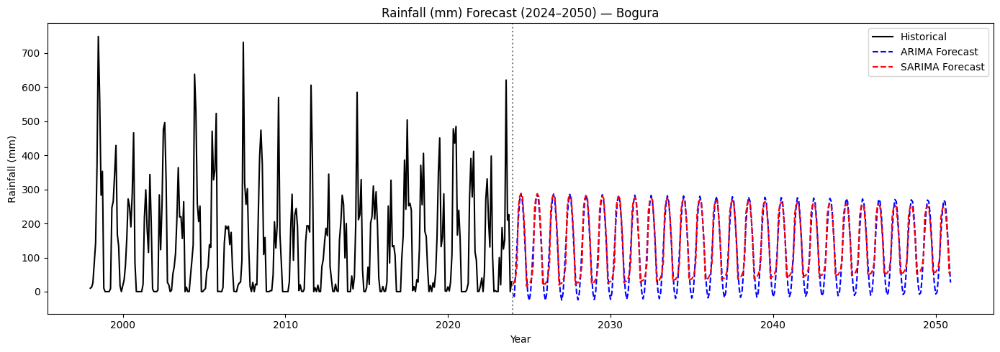

In [ ]:
example_loc = df_idx['Location'].unique()[0]
example_var = 'Rainfall (mm)'

hist = df_idx[df_idx['Location'] == example_loc][['Date', example_var]]
fc = forecast_df[(forecast_df['Location'] == example_loc) & (forecast_df['Variable'] == example_var)]

plt.figure(figsize=(14,5))
plt.plot(hist['Date'], hist[example_var], label='Historical', color='black')
plt.plot(fc['Date'], fc['ARIMA_forecast'], label='ARIMA Forecast', linestyle='--', color='blue')
plt.plot(fc['Date'], fc['SARIMA_forecast'], label='SARIMA Forecast', linestyle='--', color='red')
plt.axvline(forecast_start, color='gray', linestyle=':')
plt.title(f"{example_var} Forecast (2024–2050) — {example_loc}")
plt.xlabel("Year")
plt.ylabel(example_var)
plt.legend()
plt.tight_layout()
plt.show()

**Build Combined Historical + Forecast Dataset (Using SARIMA, Best Model)**

In [ ]:
# Use SARIMA forecasts (our improved model) to build the future dataset
future_wide = forecast_df.pivot_table(index=['Location','Date'], columns='Variable',
                                        values='SARIMA_forecast').reset_index()
future_wide['Year'] = future_wide['Date'].dt.year
future_wide['Month'] = future_wide['Date'].dt.month

# Recreate PET and WaterBalance for the forecast period
future_wide['PET'] = future_wide.apply(
    lambda row: hargreaves_pet(row['Max temp (°C)'], row['Min temp (°C)'],
                                 station_lat[row['Location']], row['Month'], row['Year']),
    axis=1
)
future_wide['WaterBalance'] = future_wide['Rainfall (mm)'] - future_wide['PET']

# Combine with historical data (only shared columns)
shared_cols = ['Location','Date','Year','Month'] + weather_vars + ['PET','WaterBalance']
combined_df = pd.concat([df_idx[shared_cols], future_wide[shared_cols]], ignore_index=True)
combined_df = combined_df.sort_values(['Location','Date']).reset_index(drop=True)

print("✅ Combined historical + forecast dataset built")
print("Shape:", combined_df.shape)
print("Date range:", combined_df['Date'].min(), "to", combined_df['Date'].max())

✅ Combined historical + forecast dataset built
Shape: (3816, 13)
Date range: 1998-01-01 00:00:00 to 2050-12-01 00:00:00


**Recompute SPI, SPEI, ZSI for Combined (Historical + Forecast) Period**

In [ ]:
scales = [1, 3, 6, 12, 24]

for loc in combined_df['Location'].unique():
    mask = combined_df['Location'] == loc
    sub = combined_df.loc[mask]

    for scale in scales:
        combined_df.loc[mask, f'SPI_{scale}'] = compute_spi(sub['Rainfall (mm)'], sub['Date'], scale)
        combined_df.loc[mask, f'SPEI_{scale}'] = compute_spei(sub['WaterBalance'], sub['Date'], scale)
        combined_df.loc[mask, f'ZSI_{scale}'] = compute_zsi(sub['Rainfall (mm)'], sub['Date'], scale)

# Add drought classification
index_cols_combined = [c for c in combined_df.columns if c.startswith(('SPI_','SPEI_','ZSI_'))]
for col in index_cols_combined:
    combined_df[f'{col}_class'] = combined_df[col].apply(classify_drought)

print("✅ SPI/SPEI/ZSI recomputed for full historical + forecast period (1998–2050)")
combined_df.to_csv("combined_historical_forecast_data.csv", index=False)
print("Saved: combined_historical_forecast_data.csv")

✅ SPI/SPEI/ZSI recomputed for full historical + forecast period (1998–2050)
Saved: combined_historical_forecast_data.csv


**(Setup): Feature Engineering — Add Lagged SPI-3 Features**

In [ ]:
LAG_MONTHS = [1, 2, 3]

df_idx = df_idx.sort_values(['Location', 'Date']).reset_index(drop=True)

for lag in LAG_MONTHS:
    df_idx[f'SPI_3_lag{lag}'] = df_idx.groupby('Location')['SPI_3'].shift(lag)

print("✅ Lagged SPI-3 features added:", [f'SPI_3_lag{l}' for l in LAG_MONTHS])
df_idx[['Location', 'Date', 'SPI_3'] + [f'SPI_3_lag{l}' for l in LAG_MONTHS]].dropna().head(10)

✅ Lagged SPI-3 features added: ['SPI_3_lag1', 'SPI_3_lag2', 'SPI_3_lag3']


,Location,Date,SPI_3,SPI_3_lag1,SPI_3_lag2,SPI_3_lag3
5,Bogura,1998-06-01,0.052966,-0.491660,0.267404,0.354692
6,Bogura,1998-07-01,1.484557,0.052966,-0.491660,0.267404
7,Bogura,1998-08-01,2.257503,1.484557,0.052966,-0.491660
8,Bogura,1998-09-01,2.597663,2.257503,1.484557,0.052966
9,Bogura,1998-10-01,2.064760,2.597663,2.257503,1.484557
10,Bogura,1998-11-01,1.547938,2.064760,2.597663,2.257503
11,Bogura,1998-12-01,1.497854,1.547938,2.064760,2.597663
12,Bogura,1999-01-01,0.060642,1.497854,1.547938,2.064760
13,Bogura,1999-02-01,-0.706303,0.060642,1.497854,1.547938
14,Bogura,1999-03-01,-1.198380,-0.706303,0.060642,1.497854


**Configuration — Target Index, Features, Train/Test Split**

In [ ]:
TARGET_INDEX = 'SPI_3'
FEATURE_COLS = ['Rainfall (mm)', 'Max temp (°C)', 'Min temp (°C)',
                 'Wind speed (m/s)', 'Sunshine (Hours)', 'Humidity (%)', 'Cloud coverage (Octs)',
                 'SPI_3_lag1', 'SPI_3_lag2', 'SPI_3_lag3']

print(f"Target variable: {TARGET_INDEX}")
print(f"Feature variables: {FEATURE_COLS}")

def prepare_station_dataset(df, location, target_col, feature_cols, test_size=0.2, random_state=42):
    """Prepare train/test split for one station, dropping rows with NaN target/features."""
    sub = df[df['Location'] == location][feature_cols + [target_col]].dropna()
    X = sub[feature_cols]
    y = sub[target_col]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )
    return X_train, X_test, y_train, y_test

print("✅ Dataset preparation function ready")

Target variable: SPI_3
Feature variables: ['Rainfall (mm)', 'Max temp (°C)', 'Min temp (°C)', 'Wind speed (m/s)', 'Sunshine (Hours)', 'Humidity (%)', 'Cloud coverage (Octs)', 'SPI_3_lag1', 'SPI_3_lag2', 'SPI_3_lag3']
✅ Dataset preparation function ready


**Evaluation Metrics Function (Classification + Regression + NSE/KGE/Kruskal-Wallis)**

In [ ]:
def nse_score(y_true, y_pred):
    """Nash-Sutcliffe Efficiency"""
    return 1 - (np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2))

def kge_score(y_true, y_pred):
    """Kling-Gupta Efficiency"""
    r = np.corrcoef(y_true, y_pred)[0, 1]
    alpha = np.std(y_pred) / np.std(y_true)
    beta = np.mean(y_pred) / np.mean(y_true)
    return 1 - np.sqrt((r - 1) ** 2 + (alpha - 1) ** 2 + (beta - 1) ** 2)

# Ordinal encoding for drought categories (for classification metrics)
class_order = ['Extreme drought', 'Severe drought', 'Moderate drought', 'Mild drought', 'No drought']
class_to_num = {c: i for i, c in enumerate(class_order)}

def to_class_labels(values):
    """Convert continuous SPI/SPEI values into drought class labels (encoded as integers)."""
    classes = pd.Series(values).apply(classify_drought)
    return classes.map(class_to_num).values

def evaluate_model(y_true, y_pred):
    """Compute full metric set: classification metrics (via thresholding) + regression metrics."""
    y_true_class = to_class_labels(y_true)
    y_pred_class = to_class_labels(y_pred)

    acc = accuracy_score(y_true_class, y_pred_class)
    prec = precision_score(y_true_class, y_pred_class, average='weighted', zero_division=0)
    rec = recall_score(y_true_class, y_pred_class, average='weighted', zero_division=0)
    f1 = f1_score(y_true_class, y_pred_class, average='weighted', zero_division=0)

    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    nse = nse_score(np.array(y_true), np.array(y_pred))
    kge = kge_score(np.array(y_true), np.array(y_pred))
    kw_stat, kw_p = kruskal(y_true, y_pred)

    return {
        'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1,
        'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2,
        'NSE': nse, 'KGE': kge, 'KW_pvalue': kw_p
    }

print("✅ Evaluation metrics function ready")

✅ Evaluation metrics function ready


**Generic Train & Evaluate Wrapper (Per Station, Train + Test Phases)**

In [ ]:
def train_evaluate_model(model_builder_fn, model_name, df, locations, target_col, feature_cols):
    """
    Train and evaluate a model per station.
    model_builder_fn: a function that returns a fresh (untrained) model instance.
    Returns a DataFrame with one row per (Location, Phase).
    """
    results = []
    for loc in locations:
        X_train, X_test, y_train, y_test = prepare_station_dataset(df, loc, target_col, feature_cols)

        model = model_builder_fn()
        model.fit(X_train, y_train)

        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)

        train_metrics = evaluate_model(y_train, y_train_pred)
        test_metrics = evaluate_model(y_test, y_test_pred)

        results.append({'Model': model_name, 'Location': loc, 'Phase': 'Training', **train_metrics})
        results.append({'Model': model_name, 'Location': loc, 'Phase': 'Testing', **test_metrics})

    return pd.DataFrame(results)

locations_list = df_idx['Location'].unique().tolist()
print("✅ Generic train/evaluate wrapper ready")
print("Stations:", locations_list)

✅ Generic train/evaluate wrapper ready
Stations: ['Bogura', 'Dinajpur', 'Ishwardi', 'Rajshahi', 'Rangpur', 'Syedpur']


**Random Forest (RF)**

In [ ]:
from sklearn.ensemble import RandomForestRegressor

def build_rf():
    return RandomForestRegressor(n_estimators=100, criterion='squared_error', max_depth=None,
                                   min_samples_split=2, min_samples_leaf=1, max_features='sqrt',
                                   random_state=42)

rf_results = train_evaluate_model(build_rf, 'RF', df_idx, locations_list, TARGET_INDEX, FEATURE_COLS)
print(rf_results.round(4))

   Model  Location     Phase  Accuracy  Precision  Recall      F1     MAE  \
0     RF    Bogura  Training    0.8857     0.8736  0.8857  0.8747  0.1799   
1     RF    Bogura   Testing    0.6613     0.5816  0.6613  0.6101  0.5522   
2     RF  Dinajpur  Training    0.8490     0.8485  0.8490  0.8424  0.1854   
3     RF  Dinajpur   Testing    0.6290     0.5245  0.6290  0.5718  0.4564   
4     RF  Ishwardi  Training    0.9102     0.9052  0.9102  0.9051  0.1800   
5     RF  Ishwardi   Testing    0.6129     0.5691  0.6129  0.5801  0.5891   
6     RF  Rajshahi  Training    0.8286     0.8186  0.8286  0.8160  0.1923   
7     RF  Rajshahi   Testing    0.6129     0.5775  0.6129  0.5706  0.5853   
8     RF   Rangpur  Training    0.8327     0.8231  0.8327  0.8178  0.1900   
9     RF   Rangpur   Testing    0.5968     0.5210  0.5968  0.5562  0.5100   
10    RF   Syedpur  Training    0.8286     0.8046  0.8286  0.8130  0.2020   
11    RF   Syedpur   Testing    0.6935     0.6179  0.6935  0.6510  0.5048   

**Support Vector Regression (SVM/SVR)**

In [ ]:
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def build_svm():
    return make_pipeline(StandardScaler(),
                          SVR(C=1.0, kernel='rbf', degree=3, gamma='scale', coef0=0.0, tol=0.001))

svm_results = train_evaluate_model(build_svm, 'SVM', df_idx, locations_list, TARGET_INDEX, FEATURE_COLS)
print(svm_results.round(4))

   Model  Location     Phase  Accuracy  Precision  Recall      F1     MAE  \
0    SVM    Bogura  Training    0.7673     0.7761  0.7673  0.7632  0.3272   
1    SVM    Bogura   Testing    0.6935     0.6616  0.6935  0.6676  0.4539   
2    SVM  Dinajpur  Training    0.8000     0.8072  0.8000  0.7955  0.2910   
3    SVM  Dinajpur   Testing    0.7742     0.7520  0.7742  0.7371  0.3408   
4    SVM  Ishwardi  Training    0.7347     0.6979  0.7347  0.7123  0.3535   
5    SVM  Ishwardi   Testing    0.6129     0.5637  0.6129  0.5846  0.5773   
6    SVM  Rajshahi  Training    0.7265     0.7152  0.7265  0.7176  0.3313   
7    SVM  Rajshahi   Testing    0.6613     0.6200  0.6613  0.6352  0.4589   
8    SVM   Rangpur  Training    0.7837     0.7632  0.7837  0.7703  0.2835   
9    SVM   Rangpur   Testing    0.6774     0.6390  0.6774  0.6549  0.4582   
10   SVM   Syedpur  Training    0.7429     0.7579  0.7429  0.7367  0.3158   
11   SVM   Syedpur   Testing    0.6129     0.6072  0.6129  0.5982  0.4954   

**Gradient Boosting (GB)**

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

def build_gb():
    return GradientBoostingRegressor(loss='squared_error', learning_rate=0.1, n_estimators=100,
                                       subsample=1.0, max_depth=3, random_state=42)

gb_results = train_evaluate_model(build_gb, 'GB', df_idx, locations_list, TARGET_INDEX, FEATURE_COLS)
print(gb_results.round(4))

   Model  Location     Phase  Accuracy  Precision  Recall      F1     MAE  \
0     GB    Bogura  Training    0.8694     0.8642  0.8694  0.8635  0.1733   
1     GB    Bogura   Testing    0.6452     0.6223  0.6452  0.6245  0.5107   
2     GB  Dinajpur  Training    0.8816     0.8881  0.8816  0.8818  0.1524   
3     GB  Dinajpur   Testing    0.7581     0.7197  0.7581  0.7172  0.3735   
4     GB  Ishwardi  Training    0.8449     0.8421  0.8449  0.8414  0.1544   
5     GB  Ishwardi   Testing    0.5484     0.5150  0.5484  0.5299  0.6086   
6     GB  Rajshahi  Training    0.8490     0.8610  0.8490  0.8503  0.1752   
7     GB  Rajshahi   Testing    0.6290     0.6363  0.6290  0.6164  0.4912   
8     GB   Rangpur  Training    0.8735     0.8731  0.8735  0.8709  0.1451   
9     GB   Rangpur   Testing    0.6774     0.7029  0.6774  0.6773  0.4705   
10    GB   Syedpur  Training    0.8490     0.8499  0.8490  0.8432  0.1647   
11    GB   Syedpur   Testing    0.6935     0.6694  0.6935  0.6804  0.5099   

**XGBoost (XGB)**

In [ ]:
from xgboost import XGBRegressor

def build_xgb():
    return XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=6, min_child_weight=1,
                          gamma=0, subsample=1, colsample_bytree=1, objective='reg:squarederror',
                          random_state=42, verbosity=0)

xgb_results = train_evaluate_model(build_xgb, 'XGB', df_idx, locations_list, TARGET_INDEX, FEATURE_COLS)
print(xgb_results.round(4))

   Model  Location     Phase  Accuracy  Precision  Recall      F1     MAE  \
0    XGB    Bogura  Training    0.9755     0.9770  0.9755  0.9754  0.0170   
1    XGB    Bogura   Testing    0.6129     0.6298  0.6129  0.6030  0.5811   
2    XGB  Dinajpur  Training    0.9878     0.9880  0.9878  0.9875  0.0192   
3    XGB  Dinajpur   Testing    0.7258     0.7172  0.7258  0.7080  0.3699   
4    XGB  Ishwardi  Training    0.9755     0.9755  0.9755  0.9747  0.0315   
5    XGB  Ishwardi   Testing    0.5806     0.5457  0.5806  0.5624  0.6181   
6    XGB  Rajshahi  Training    0.9592     0.9611  0.9592  0.9595  0.0286   
7    XGB  Rajshahi   Testing    0.5484     0.5818  0.5484  0.5499  0.5473   
8    XGB   Rangpur  Training    0.9959     0.9960  0.9959  0.9959  0.0147   
9    XGB   Rangpur   Testing    0.6935     0.6659  0.6935  0.6784  0.4849   
10   XGB   Syedpur  Training    0.9837     0.9839  0.9837  0.9837  0.0189   
11   XGB   Syedpur   Testing    0.6935     0.6591  0.6935  0.6719  0.4889   

**K-Nearest Neighbors (KNN)**

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

def build_knn():
    return make_pipeline(StandardScaler(),
                          KNeighborsRegressor(n_neighbors=5, weights='uniform', algorithm='auto',
                                                leaf_size=30, p=2, metric='minkowski'))

knn_results = train_evaluate_model(build_knn, 'KNN', df_idx, locations_list, TARGET_INDEX, FEATURE_COLS)
print(knn_results.round(4))

   Model  Location     Phase  Accuracy  Precision  Recall      F1     MAE  \
0    KNN    Bogura  Training    0.6898     0.6686  0.6898  0.6738  0.4480   
1    KNN    Bogura   Testing    0.6129     0.5975  0.6129  0.5856  0.5236   
2    KNN  Dinajpur  Training    0.6694     0.6469  0.6694  0.6522  0.4654   
3    KNN  Dinajpur   Testing    0.7097     0.6134  0.7097  0.6563  0.4788   
4    KNN  Ishwardi  Training    0.6816     0.6590  0.6816  0.6620  0.4590   
5    KNN  Ishwardi   Testing    0.5968     0.5585  0.5968  0.5730  0.6327   
6    KNN  Rajshahi  Training    0.6857     0.6824  0.6857  0.6683  0.4873   
7    KNN  Rajshahi   Testing    0.5000     0.5248  0.5000  0.4763  0.6156   
8    KNN   Rangpur  Training    0.6776     0.6581  0.6776  0.6585  0.4314   
9    KNN   Rangpur   Testing    0.6452     0.6657  0.6452  0.6435  0.5362   
10   KNN   Syedpur  Training    0.6571     0.6188  0.6571  0.6311  0.4548   
11   KNN   Syedpur   Testing    0.6290     0.5645  0.6290  0.5914  0.5877   

**Combine First 5 Models' Results**

In [ ]:
first_5_results = pd.concat([rf_results, svm_results, gb_results, xgb_results, knn_results], ignore_index=True)
first_5_results.to_csv("ml_results_part1_RF_SVM_GB_XGB_KNN.csv", index=False)

print("✅ Saved: ml_results_part1_RF_SVM_GB_XGB_KNN.csv")
print("\nTesting-phase summary (mean across stations):")
print(first_5_results[first_5_results['Phase']=='Testing'].groupby('Model')[
    ['Accuracy','Precision','Recall','F1','MAE','MSE','RMSE','R2','NSE','KGE']
].mean().round(4))

✅ Saved: ml_results_part1_RF_SVM_GB_XGB_KNN.csv

Testing-phase summary (mean across stations):
       Accuracy  Precision  Recall      F1     MAE     MSE    RMSE      R2  \
Model                                                                        
GB       0.6586     0.6443  0.6586  0.6410  0.4941  0.4328  0.6525  0.5672   
KNN      0.6156     0.5874  0.6156  0.5877  0.5624  0.5594  0.7424  0.4390   
RF       0.6344     0.5653  0.6344  0.5900  0.5330  0.4884  0.6957  0.5082   
SVM      0.6720     0.6406  0.6720  0.6462  0.4641  0.4029  0.6267  0.6007   
XGB      0.6425     0.6333  0.6425  0.6289  0.5150  0.4598  0.6731  0.5412   

          NSE     KGE  
Model                  
GB     0.5672 -1.3315  
KNN    0.4390 -2.2692  
RF     0.5082 -0.2198  
SVM    0.6007 -0.8631  
XGB    0.5412 -1.1003  


**Decision Tree (DT)**

In [ ]:
from sklearn.tree import DecisionTreeRegressor

def build_dt():
    return DecisionTreeRegressor(criterion='squared_error', splitter='best', max_depth=None,
                                   min_samples_split=2, min_samples_leaf=1, max_features=None,
                                   random_state=42)

dt_results = train_evaluate_model(build_dt, 'DT', df_idx, locations_list, TARGET_INDEX, FEATURE_COLS)
print(dt_results.round(4))

   Model  Location     Phase  Accuracy  Precision  Recall      F1     MAE  \
0     DT    Bogura  Training    1.0000     1.0000  1.0000  1.0000  0.0000   
1     DT    Bogura   Testing    0.5968     0.5741  0.5968  0.5757  0.7955   
2     DT  Dinajpur  Training    1.0000     1.0000  1.0000  1.0000  0.0000   
3     DT  Dinajpur   Testing    0.5968     0.6796  0.5968  0.5850  0.6115   
4     DT  Ishwardi  Training    1.0000     1.0000  1.0000  1.0000  0.0000   
5     DT  Ishwardi   Testing    0.4516     0.4464  0.4516  0.4471  0.9377   
6     DT  Rajshahi  Training    1.0000     1.0000  1.0000  1.0000  0.0000   
7     DT  Rajshahi   Testing    0.6129     0.6210  0.6129  0.6137  0.7175   
8     DT   Rangpur  Training    1.0000     1.0000  1.0000  1.0000  0.0000   
9     DT   Rangpur   Testing    0.4839     0.4574  0.4839  0.4681  0.8083   
10    DT   Syedpur  Training    1.0000     1.0000  1.0000  1.0000  0.0000   
11    DT   Syedpur   Testing    0.5968     0.6066  0.5968  0.6007  0.6887   

**Linear Regression (LR)**

In [ ]:
from sklearn.linear_model import LinearRegression

def build_lr():
    return LinearRegression(fit_intercept=True, copy_X=True, positive=False)

lr_results = train_evaluate_model(build_lr, 'LR', df_idx, locations_list, TARGET_INDEX, FEATURE_COLS)
print(lr_results.round(4))

   Model  Location     Phase  Accuracy  Precision  Recall      F1     MAE  \
0     LR    Bogura  Training    0.6694     0.6864  0.6694  0.6624  0.4526   
1     LR    Bogura   Testing    0.6774     0.6676  0.6774  0.6655  0.4871   
2     LR  Dinajpur  Training    0.7020     0.7227  0.7020  0.7015  0.4158   
3     LR  Dinajpur   Testing    0.7419     0.7511  0.7419  0.7339  0.3954   
4     LR  Ishwardi  Training    0.6612     0.6401  0.6612  0.6487  0.4594   
5     LR  Ishwardi   Testing    0.6129     0.5945  0.6129  0.6007  0.5269   
6     LR  Rajshahi  Training    0.6531     0.6408  0.6531  0.6422  0.4670   
7     LR  Rajshahi   Testing    0.7097     0.7121  0.7097  0.7030  0.4497   
8     LR   Rangpur  Training    0.6694     0.6700  0.6694  0.6593  0.4279   
9     LR   Rangpur   Testing    0.6452     0.6254  0.6452  0.6341  0.4528   
10    LR   Syedpur  Training    0.6367     0.6318  0.6367  0.6296  0.4574   
11    LR   Syedpur   Testing    0.5806     0.6190  0.5806  0.5811  0.5074   

**Multi-Layer Perceptron (MLP)**

In [ ]:
from sklearn.neural_network import MLPRegressor

def build_mlp():
    return make_pipeline(StandardScaler(),
                          MLPRegressor(hidden_layer_sizes=(100,), activation='relu', solver='adam',
                                        alpha=0.0001, learning_rate='constant', max_iter=2000,
                                        random_state=42))

mlp_results = train_evaluate_model(build_mlp, 'MLP', df_idx, locations_list, TARGET_INDEX, FEATURE_COLS)
print(mlp_results.round(4))

   Model  Location     Phase  Accuracy  Precision  Recall      F1     MAE  \
0    MLP    Bogura  Training    0.8122     0.8140  0.8122  0.8088  0.2742   
1    MLP    Bogura   Testing    0.7097     0.7005  0.7097  0.6930  0.4323   
2    MLP  Dinajpur  Training    0.8980     0.9029  0.8980  0.8991  0.1710   
3    MLP  Dinajpur   Testing    0.7742     0.7720  0.7742  0.7630  0.3342   
4    MLP  Ishwardi  Training    0.8286     0.8336  0.8286  0.8284  0.1620   
5    MLP  Ishwardi   Testing    0.6290     0.5970  0.6290  0.5982  0.5017   
6    MLP  Rajshahi  Training    0.8490     0.8572  0.8490  0.8507  0.1851   
7    MLP  Rajshahi   Testing    0.6129     0.5953  0.6129  0.5974  0.4474   
8    MLP   Rangpur  Training    0.8449     0.8473  0.8449  0.8418  0.1915   
9    MLP   Rangpur   Testing    0.6774     0.6812  0.6774  0.6703  0.4682   
10   MLP   Syedpur  Training    0.8980     0.9065  0.8980  0.8997  0.1016   
11   MLP   Syedpur   Testing    0.5806     0.5900  0.5806  0.5816  0.5179   

**Stochastic Gradient Descent (SGD)**

In [ ]:
from sklearn.linear_model import SGDRegressor

def build_sgd():
    return make_pipeline(StandardScaler(),
                          SGDRegressor(loss='squared_error', penalty='l2', alpha=0.0001,
                                        max_iter=1000, tol=0.001, shuffle=True, random_state=42))

sgd_results = train_evaluate_model(build_sgd, 'SGD', df_idx, locations_list, TARGET_INDEX, FEATURE_COLS)
print(sgd_results.round(4))

   Model  Location     Phase  Accuracy  Precision  Recall      F1     MAE  \
0    SGD    Bogura  Training    0.6694     0.6964  0.6694  0.6581  0.4563   
1    SGD    Bogura   Testing    0.6613     0.6480  0.6613  0.6447  0.4895   
2    SGD  Dinajpur  Training    0.6980     0.7043  0.6980  0.6908  0.4192   
3    SGD  Dinajpur   Testing    0.6935     0.6898  0.6935  0.6721  0.3980   
4    SGD  Ishwardi  Training    0.6612     0.6376  0.6612  0.6471  0.4572   
5    SGD  Ishwardi   Testing    0.6290     0.6043  0.6290  0.6130  0.5570   
6    SGD  Rajshahi  Training    0.6245     0.6174  0.6245  0.6156  0.4746   
7    SGD  Rajshahi   Testing    0.7097     0.7282  0.7097  0.7036  0.4543   
8    SGD   Rangpur  Training    0.6653     0.6409  0.6653  0.6505  0.4336   
9    SGD   Rangpur   Testing    0.5968     0.5696  0.5968  0.5828  0.4566   
10   SGD   Syedpur  Training    0.6286     0.6258  0.6286  0.6202  0.4578   
11   SGD   Syedpur   Testing    0.5968     0.6296  0.5968  0.5977  0.4907   

**Stacking Ensemble (Base: XGB, MLP, SVR, RF | Meta: LR)**

In [ ]:
from sklearn.ensemble import StackingRegressor

def build_ensemble():
    base_learners = [
        ('xgb', XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=6,
                               objective='reg:squarederror', random_state=42, verbosity=0)),
        ('mlp', make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(100,),
                                activation='relu', solver='adam', max_iter=2000, random_state=42))),
        ('svr', make_pipeline(StandardScaler(), SVR(C=1.0, kernel='rbf', gamma='scale'))),
        ('rf', RandomForestRegressor(n_estimators=100, max_features='sqrt', random_state=42))
    ]
    meta_learner = LinearRegression()
    return StackingRegressor(estimators=base_learners, final_estimator=meta_learner, cv=5)

ensemble_results = train_evaluate_model(build_ensemble, 'Ensemble', df_idx, locations_list, TARGET_INDEX, FEATURE_COLS)
print(ensemble_results.round(4))

       Model  Location     Phase  Accuracy  Precision  Recall      F1     MAE  \
0   Ensemble    Bogura  Training    0.8898     0.8829  0.8898  0.8850  0.1705   
1   Ensemble    Bogura   Testing    0.6290     0.5616  0.6290  0.5889  0.4698   
2   Ensemble  Dinajpur  Training    0.9102     0.9107  0.9102  0.9101  0.1345   
3   Ensemble  Dinajpur   Testing    0.7097     0.7024  0.7097  0.6863  0.3109   
4   Ensemble  Ishwardi  Training    0.9061     0.9092  0.9061  0.9053  0.0952   
5   Ensemble  Ishwardi   Testing    0.5968     0.5490  0.5968  0.5705  0.5413   
6   Ensemble  Rajshahi  Training    0.8816     0.8885  0.8816  0.8826  0.1358   
7   Ensemble  Rajshahi   Testing    0.5968     0.5876  0.5968  0.5860  0.4681   
8   Ensemble   Rangpur  Training    0.8612     0.8673  0.8612  0.8559  0.1718   
9   Ensemble   Rangpur   Testing    0.7742     0.7776  0.7742  0.7668  0.4380   
10  Ensemble   Syedpur  Training    0.8245     0.8413  0.8245  0.8238  0.2003   
11  Ensemble   Syedpur   Tes

**Combine All 10 ML Models' Results**

In [ ]:
last_5_results = pd.concat([dt_results, lr_results, mlp_results, sgd_results, ensemble_results], ignore_index=True)
last_5_results.to_csv("ml_results_part2_DT_LR_MLP_SGD_Ensemble.csv", index=False)

# Combine with first 5 for the complete ML results table
all_ml_results = pd.concat([first_5_results, last_5_results], ignore_index=True)
all_ml_results.to_csv("ml_results_all_10_models.csv", index=False)

print("✅ Saved: ml_results_part2_DT_LR_MLP_SGD_Ensemble.csv")
print("✅ Saved: ml_results_all_10_models.csv (combined)")

print("\n=== FULL ML MODEL COMPARISON — Testing Phase (mean across stations) ===")
summary_table = all_ml_results[all_ml_results['Phase']=='Testing'].groupby('Model')[
    ['Accuracy','Precision','Recall','F1','MAE','MSE','RMSE','R2','NSE','KGE']
].mean().round(4).sort_values('R2', ascending=False)
print(summary_table)

✅ Saved: ml_results_part2_DT_LR_MLP_SGD_Ensemble.csv
✅ Saved: ml_results_all_10_models.csv (combined)

=== FULL ML MODEL COMPARISON — Testing Phase (mean across stations) ===
          Accuracy  Precision  Recall      F1     MAE     MSE    RMSE      R2  \
Model                                                                           
Ensemble    0.6532     0.6308  0.6532  0.6333  0.4505  0.3517  0.5888  0.6466   
MLP         0.6640     0.6560  0.6640  0.6506  0.4503  0.3837  0.6130  0.6147   
SVM         0.6720     0.6406  0.6720  0.6462  0.4641  0.4029  0.6267  0.6007   
LR          0.6613     0.6616  0.6613  0.6531  0.4699  0.3984  0.6283  0.5953   
SGD         0.6478     0.6449  0.6478  0.6356  0.4743  0.4022  0.6309  0.5936   
GB          0.6586     0.6443  0.6586  0.6410  0.4941  0.4328  0.6525  0.5672   
XGB         0.6425     0.6333  0.6425  0.6289  0.5150  0.4598  0.6731  0.5412   
RF          0.6344     0.5653  0.6344  0.5900  0.5330  0.4884  0.6957  0.5082   
KNN         0.6

**Verify GPU & Set Random Seeds**

In [ ]:
print("GPU available:", tf.config.list_physical_devices('GPU'))

# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

from tensorflow.keras.callbacks import EarlyStopping

GPU available: []


**Sequence Creation Function**

In [ ]:
LOOKBACK = 12  # use past 12 months to predict next month's SPI/SPEI value

def create_sequences(df, location, feature_cols, target_col, lookback=LOOKBACK):
    """Create sliding-window sequences (X) and next-step target (y) for one station."""
    sub = df[df['Location'] == location][feature_cols + [target_col]].dropna().reset_index(drop=True)
    values = sub[feature_cols].values
    target = sub[target_col].values

    X, y = [], []
    for i in range(lookback, len(sub)):
        X.append(values[i - lookback:i])
        y.append(target[i])
    return np.array(X), np.array(y)

print(f"✅ Sequence creation function ready (lookback = {LOOKBACK} months)")

✅ Sequence creation function ready (lookback = 12 months)


**Generic DL Train & Evaluate Wrapper (Per Station, Train + Test Phases)**

In [ ]:
def scale_sequences(X_train, X_test):
    """Scale 3D sequence arrays using StandardScaler fit on training data only."""
    n_features = X_train.shape[2]
    scaler = StandardScaler()

    X_train_2d = X_train.reshape(-1, n_features)
    scaler.fit(X_train_2d)

    X_train_scaled = scaler.transform(X_train_2d).reshape(X_train.shape)
    X_test_scaled = scaler.transform(X_test.reshape(-1, n_features)).reshape(X_test.shape)
    return X_train_scaled, X_test_scaled

def train_evaluate_dl_model(model_builder_fn, model_name, df, locations, target_col, feature_cols,
                              lookback=LOOKBACK, epochs=100, batch_size=16, verbose=0):
    """
    Train and evaluate a Keras DL model per station.
    model_builder_fn: function(input_shape) -> compiled Keras model
    Returns a DataFrame with one row per (Location, Phase), same format as ML results.
    """
    results = []
    for loc in locations:
        X, y = create_sequences(df, loc, feature_cols, target_col, lookback)

        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42
        )
        X_train_s, X_test_s = scale_sequences(X_train, X_test)

        model = model_builder_fn(input_shape=(lookback, len(feature_cols)))
        early_stop = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)

        model.fit(X_train_s, y_train, epochs=epochs, batch_size=batch_size,
                  callbacks=[early_stop], verbose=verbose)

        y_train_pred = model.predict(X_train_s, verbose=0).flatten()
        y_test_pred = model.predict(X_test_s, verbose=0).flatten()

        train_metrics = evaluate_model(y_train, y_train_pred)
        test_metrics = evaluate_model(y_test, y_test_pred)

        results.append({'Model': model_name, 'Location': loc, 'Phase': 'Training', **train_metrics})
        results.append({'Model': model_name, 'Location': loc, 'Phase': 'Testing', **test_metrics})

        print(f"  {model_name} — {loc} done")

    return pd.DataFrame(results)

print("✅ Generic DL train/evaluate wrapper ready")

✅ Generic DL train/evaluate wrapper ready


**LSTM**

In [ ]:
def build_lstm(input_shape):
    model = Sequential([
        LSTM(64, activation='tanh', input_shape=input_shape, return_sequences=False),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

lstm_results = train_evaluate_dl_model(build_lstm, 'LSTM', df_idx, locations_list, TARGET_INDEX, FEATURE_COLS)
print(lstm_results.round(4))

  LSTM — Bogura done
  LSTM — Dinajpur done
  LSTM — Ishwardi done
  LSTM — Rajshahi done
  LSTM — Rangpur done
  LSTM — Syedpur done
   Model  Location     Phase  Accuracy  Precision  Recall      F1     MAE  \
0   LSTM    Bogura  Training    0.8559     0.8617  0.8559  0.8546  0.2058   
1   LSTM    Bogura   Testing    0.6441     0.6755  0.6441  0.5997  0.6059   
2   LSTM  Dinajpur  Training    0.8941     0.8944  0.8941  0.8927  0.1461   
3   LSTM  Dinajpur   Testing    0.5593     0.6343  0.5593  0.5712  0.6291   
4   LSTM  Ishwardi  Training    0.8475     0.8534  0.8475  0.8450  0.2143   
5   LSTM  Ishwardi   Testing    0.6949     0.6928  0.6949  0.6924  0.5134   
6   LSTM  Rajshahi  Training    0.8686     0.8852  0.8686  0.8728  0.1573   
7   LSTM  Rajshahi   Testing    0.5763     0.6010  0.5763  0.5855  0.6687   
8   LSTM   Rangpur  Training    0.8602     0.8605  0.8602  0.8580  0.1900   
9   LSTM   Rangpur   Testing    0.5424     0.5035  0.5424  0.5214  0.6379   
10  LSTM   Syedpur 

**GRU**

In [ ]:
def build_gru(input_shape):
    model = Sequential([
        GRU(64, activation='tanh', input_shape=input_shape, return_sequences=False),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

gru_results = train_evaluate_dl_model(build_gru, 'GRU', df_idx, locations_list, TARGET_INDEX, FEATURE_COLS)
print(gru_results.round(4))

  GRU — Bogura done
  GRU — Dinajpur done
  GRU — Ishwardi done
  GRU — Rajshahi done
  GRU — Rangpur done
  GRU — Syedpur done
   Model  Location     Phase  Accuracy  Precision  Recall      F1     MAE  \
0    GRU    Bogura  Training    0.9025     0.9118  0.9025  0.9025  0.1507   
1    GRU    Bogura   Testing    0.6441     0.5974  0.6441  0.6050  0.6674   
2    GRU  Dinajpur  Training    0.8814     0.8814  0.8814  0.8784  0.1439   
3    GRU  Dinajpur   Testing    0.5085     0.4960  0.5085  0.4946  0.7613   
4    GRU  Ishwardi  Training    0.8559     0.8587  0.8559  0.8521  0.1667   
5    GRU  Ishwardi   Testing    0.7288     0.7060  0.7288  0.7130  0.5317   
6    GRU  Rajshahi  Training    0.8898     0.8984  0.8898  0.8913  0.1429   
7    GRU  Rajshahi   Testing    0.5593     0.5907  0.5593  0.5660  0.6803   
8    GRU   Rangpur  Training    0.9025     0.9045  0.9025  0.9026  0.1563   
9    GRU   Rangpur   Testing    0.5593     0.5048  0.5593  0.5281  0.6987   
10   GRU   Syedpur  Train

**Bidirectional LSTM (Bi-LSTM)**

In [ ]:
def build_bilstm(input_shape):
    model = Sequential([
        Bidirectional(LSTM(64, activation='tanh', return_sequences=False), input_shape=input_shape),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

bilstm_results = train_evaluate_dl_model(build_bilstm, 'Bi-LSTM', df_idx, locations_list, TARGET_INDEX, FEATURE_COLS)
print(bilstm_results.round(4))

  Bi-LSTM — Bogura done
  Bi-LSTM — Dinajpur done
  Bi-LSTM — Ishwardi done
  Bi-LSTM — Rajshahi done
  Bi-LSTM — Rangpur done
  Bi-LSTM — Syedpur done
      Model  Location     Phase  Accuracy  Precision  Recall      F1     MAE  \
0   Bi-LSTM    Bogura  Training    0.9068     0.9144  0.9068  0.9077  0.1347   
1   Bi-LSTM    Bogura   Testing    0.6271     0.6032  0.6271  0.6050  0.5950   
2   Bi-LSTM  Dinajpur  Training    0.9110     0.9102  0.9110  0.9104  0.1221   
3   Bi-LSTM  Dinajpur   Testing    0.4915     0.5240  0.4915  0.4979  0.6785   
4   Bi-LSTM  Ishwardi  Training    0.8898     0.8939  0.8898  0.8888  0.1208   
5   Bi-LSTM  Ishwardi   Testing    0.6271     0.6141  0.6271  0.6188  0.5589   
6   Bi-LSTM  Rajshahi  Training    0.8644     0.8768  0.8644  0.8681  0.1431   
7   Bi-LSTM  Rajshahi   Testing    0.5424     0.5620  0.5424  0.5505  0.7059   
8   Bi-LSTM   Rangpur  Training    0.9153     0.9171  0.9153  0.9156  0.1135   
9   Bi-LSTM   Rangpur   Testing    0.5932     0.

**CNN-LSTM Hybrid**

In [ ]:
def build_cnn_lstm(input_shape):
    model = Sequential([
        Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=input_shape),
        MaxPooling1D(pool_size=2),
        LSTM(64, activation='tanh', return_sequences=False),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

cnn_lstm_results = train_evaluate_dl_model(build_cnn_lstm, 'CNN-LSTM', df_idx, locations_list, TARGET_INDEX, FEATURE_COLS)
print(cnn_lstm_results.round(4))

  CNN-LSTM — Bogura done
  CNN-LSTM — Dinajpur done
  CNN-LSTM — Ishwardi done
  CNN-LSTM — Rajshahi done
  CNN-LSTM — Rangpur done
  CNN-LSTM — Syedpur done
       Model  Location     Phase  Accuracy  Precision  Recall      F1     MAE  \
0   CNN-LSTM    Bogura  Training    0.8136     0.8207  0.8136  0.8015  0.2312   
1   CNN-LSTM    Bogura   Testing    0.5763     0.5275  0.5763  0.5323  0.6970   
2   CNN-LSTM  Dinajpur  Training    0.8729     0.8720  0.8729  0.8663  0.1308   
3   CNN-LSTM  Dinajpur   Testing    0.5593     0.6059  0.5593  0.5594  0.7085   
4   CNN-LSTM  Ishwardi  Training    0.8220     0.8308  0.8220  0.8162  0.2222   
5   CNN-LSTM  Ishwardi   Testing    0.6441     0.6507  0.6441  0.6381  0.5584   
6   CNN-LSTM  Rajshahi  Training    0.9322     0.9327  0.9322  0.9305  0.1253   
7   CNN-LSTM  Rajshahi   Testing    0.6102     0.5797  0.6102  0.5932  0.6469   
8   CNN-LSTM   Rangpur  Training    0.8178     0.8317  0.8178  0.8206  0.2565   
9   CNN-LSTM   Rangpur   Testing

**Combine All DL Model Results**

In [ ]:
all_dl_results = pd.concat([lstm_results, gru_results, bilstm_results, cnn_lstm_results], ignore_index=True)
all_dl_results.to_csv("dl_results_all_4_models.csv", index=False)

print("✅ Saved: dl_results_all_4_models.csv")

print("\n=== DL MODEL COMPARISON — Testing Phase (mean across stations) ===")
dl_summary = all_dl_results[all_dl_results['Phase']=='Testing'].groupby('Model')[
    ['Accuracy','Precision','Recall','F1','MAE','MSE','RMSE','R2','NSE','KGE']
].mean().round(4).sort_values('R2', ascending=False)
print(dl_summary)

✅ Saved: dl_results_all_4_models.csv

=== DL MODEL COMPARISON — Testing Phase (mean across stations) ===
          Accuracy  Precision  Recall      F1     MAE     MSE    RMSE      R2  \
Model                                                                           
Bi-LSTM     0.5678     0.5669  0.5678  0.5620  0.6203  0.6468  0.8028  0.3433   
LSTM        0.5989     0.6168  0.5989  0.5913  0.6182  0.6656  0.8151  0.3234   
CNN-LSTM    0.5932     0.5953  0.5932  0.5803  0.6487  0.6665  0.8154  0.3185   
GRU         0.5960     0.5792  0.5960  0.5789  0.6765  0.7443  0.8612  0.2441   

             NSE      KGE  
Model                      
Bi-LSTM   0.3433  -7.7565  
LSTM      0.3234  -9.9738  
CNN-LSTM  0.3185 -12.1751  
GRU       0.2441  -8.9777  


**Combine All ML + DL Results into Master Table**

In [ ]:
master_results = pd.concat([all_ml_results, all_dl_results], ignore_index=True)
master_results.to_csv("master_results_all_14_models.csv", index=False)

print("✅ Saved: master_results_all_14_models.csv")
print(f"Total models compared: {master_results['Model'].nunique()}")
print(master_results['Model'].unique())

print("\n=== FULL MODEL COMPARISON — Testing Phase (mean across 6 stations) ===")
master_summary = master_results[master_results['Phase']=='Testing'].groupby('Model')[
    ['Accuracy','Precision','Recall','F1','MAE','MSE','RMSE','R2','NSE','KGE']
].mean().round(4).sort_values('R2', ascending=False)
print(master_summary)
master_summary.to_csv("master_summary_testing_phase.csv")

✅ Saved: master_results_all_14_models.csv
Total models compared: 14
['RF' 'SVM' 'GB' 'XGB' 'KNN' 'DT' 'LR' 'MLP' 'SGD' 'Ensemble' 'LSTM' 'GRU'
 'Bi-LSTM' 'CNN-LSTM']

=== FULL MODEL COMPARISON — Testing Phase (mean across 6 stations) ===
          Accuracy  Precision  Recall      F1     MAE     MSE    RMSE      R2  \
Model                                                                           
Ensemble    0.6532     0.6308  0.6532  0.6333  0.4505  0.3517  0.5888  0.6466   
MLP         0.6640     0.6560  0.6640  0.6506  0.4503  0.3837  0.6130  0.6147   
SVM         0.6720     0.6406  0.6720  0.6462  0.4641  0.4029  0.6267  0.6007   
LR          0.6613     0.6616  0.6613  0.6531  0.4699  0.3984  0.6283  0.5953   
SGD         0.6478     0.6449  0.6478  0.6356  0.4743  0.4022  0.6309  0.5936   
GB          0.6586     0.6443  0.6586  0.6410  0.4941  0.4328  0.6525  0.5672   
XGB         0.6425     0.6333  0.6425  0.6289  0.5150  0.4598  0.6731  0.5412   
RF          0.6344     0.5653  0.

**Bar Chart Comparison — Accuracy, R², RMSE Across All Models**

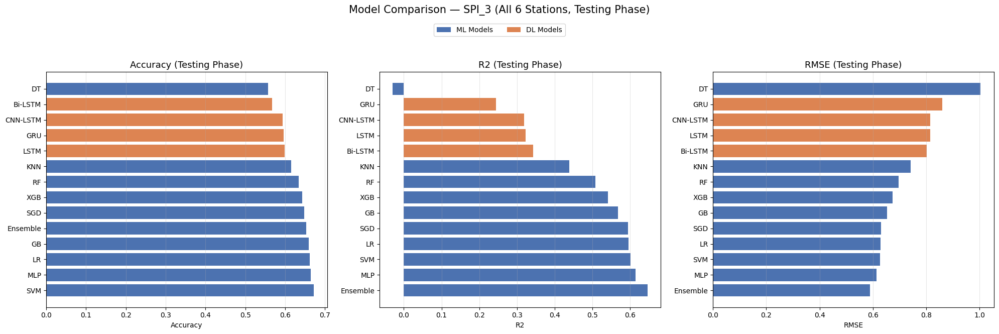

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

metrics_to_plot = ['Accuracy', 'R2', 'RMSE']
colors = ['#4C72B0' if m in ['RF','SVM','GB','XGB','KNN','DT','LR','MLP','SGD','Ensemble'] else '#DD8452'
          for m in master_summary.index]

for ax, metric in zip(axes, metrics_to_plot):
    sorted_data = master_summary[metric].sort_values(ascending=(metric=='RMSE'))
    bar_colors = ['#4C72B0' if m in ['RF','SVM','GB','XGB','KNN','DT','LR','MLP','SGD','Ensemble'] else '#DD8452'
                  for m in sorted_data.index]
    ax.barh(sorted_data.index, sorted_data.values, color=bar_colors)
    ax.set_title(f'{metric} (Testing Phase)', fontsize=13)
    ax.set_xlabel(metric)
    ax.grid(axis='x', alpha=0.3)

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#4C72B0', label='ML Models'),
                   Patch(facecolor='#DD8452', label='DL Models')]
fig.legend(handles=legend_elements, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.05))

plt.suptitle(f'Model Comparison — {TARGET_INDEX} (All 6 Stations, Testing Phase)', fontsize=15, y=1.1)
plt.tight_layout()
plt.savefig("model_comparison_bars.png", dpi=150, bbox_inches='tight')
plt.show()

**Station-wise Heatmap — Best Model Performance per Station**

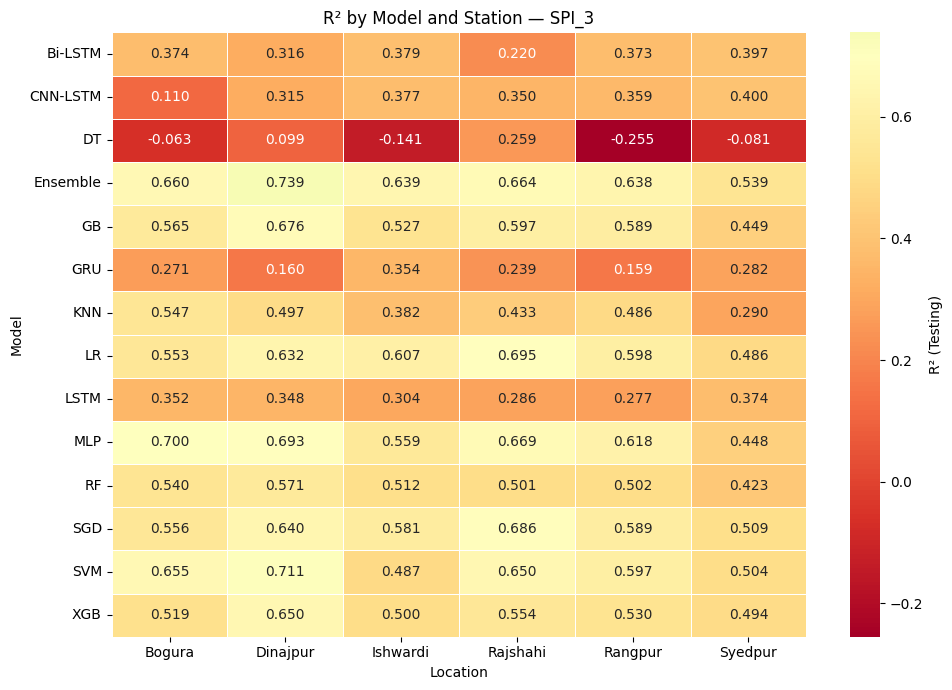

In [ ]:
station_r2 = master_results[master_results['Phase']=='Testing'].pivot_table(
    index='Model', columns='Location', values='R2'
).round(3)

plt.figure(figsize=(10, 7))
sns.heatmap(station_r2, annot=True, cmap='RdYlGn', center=0.7, fmt='.3f',
            linewidths=0.5, cbar_kws={'label': 'R² (Testing)'})
plt.title(f'R² by Model and Station — {TARGET_INDEX}')
plt.tight_layout()
plt.savefig("station_model_r2_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

**Collect Pooled Test Predictions (Actual vs Predicted) for Taylor Diagram**

In [ ]:
# Registry of all model builders (ML regressors + DL builders)
ml_builders = {
    'RF': build_rf, 'SVM': build_svm, 'GB': build_gb, 'XGB': build_xgb, 'KNN': build_knn,
    'DT': build_dt, 'LR': build_lr, 'MLP': build_mlp, 'SGD': build_sgd, 'Ensemble': build_ensemble
}
dl_builders = {
    'LSTM': build_lstm, 'GRU': build_gru, 'Bi-LSTM': build_bilstm, 'CNN-LSTM': build_cnn_lstm
}

def get_pooled_predictions_ml(model_builder_fn, df, locations, target_col, feature_cols):
    """Pool test-set actual & predicted values across all stations for one ML model."""
    all_y_true, all_y_pred = [], []
    for loc in locations:
        X_train, X_test, y_train, y_test = prepare_station_dataset(df, loc, target_col, feature_cols)
        model = model_builder_fn()
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        all_y_true.extend(y_test.values)
        all_y_pred.extend(y_pred)
    return np.array(all_y_true), np.array(all_y_pred)

def get_pooled_predictions_dl(model_builder_fn, df, locations, target_col, feature_cols,
                                lookback=LOOKBACK, epochs=100, batch_size=16):
    """Pool test-set actual & predicted values across all stations for one DL model."""
    all_y_true, all_y_pred = [], []
    for loc in locations:
        X, y = create_sequences(df, loc, feature_cols, target_col, lookback)
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
        X_train_s, X_test_s = scale_sequences(X_train, X_test)

        model = model_builder_fn(input_shape=(lookback, len(feature_cols)))
        early_stop = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)
        model.fit(X_train_s, y_train, epochs=epochs, batch_size=batch_size,
                  callbacks=[early_stop], verbose=0)

        y_pred = model.predict(X_test_s, verbose=0).flatten()
        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)
    return np.array(all_y_true), np.array(all_y_pred)

# Collect pooled predictions for ALL 14 models
pooled_predictions = {}

print("Collecting ML model predictions...")
for name, builder in ml_builders.items():
    y_true, y_pred = get_pooled_predictions_ml(builder, df_idx, locations_list, TARGET_INDEX, FEATURE_COLS)
    pooled_predictions[name] = {'y_true': y_true, 'y_pred': y_pred}
    print(f"  ✅ {name} done")

print("\nCollecting DL model predictions...")
for name, builder in dl_builders.items():
    y_true, y_pred = get_pooled_predictions_dl(builder, df_idx, locations_list, TARGET_INDEX, FEATURE_COLS)
    pooled_predictions[name] = {'y_true': y_true, 'y_pred': y_pred}
    print(f"  ✅ {name} done")

print("\n✅ Pooled predictions collected for all 14 models")

  ✅ RF done
  ✅ SVM done
  ✅ GB done
  ✅ XGB done
  ✅ KNN done
  ✅ DT done
  ✅ LR done
  ✅ MLP done
  ✅ SGD done
  ✅ Ensemble done



  ✅ LSTM done
  ✅ GRU done
  ✅ Bi-LSTM done
  ✅ CNN-LSTM done

✅ Pooled predictions collected for all 14 models


**Taylor Diagram Function & Plot**

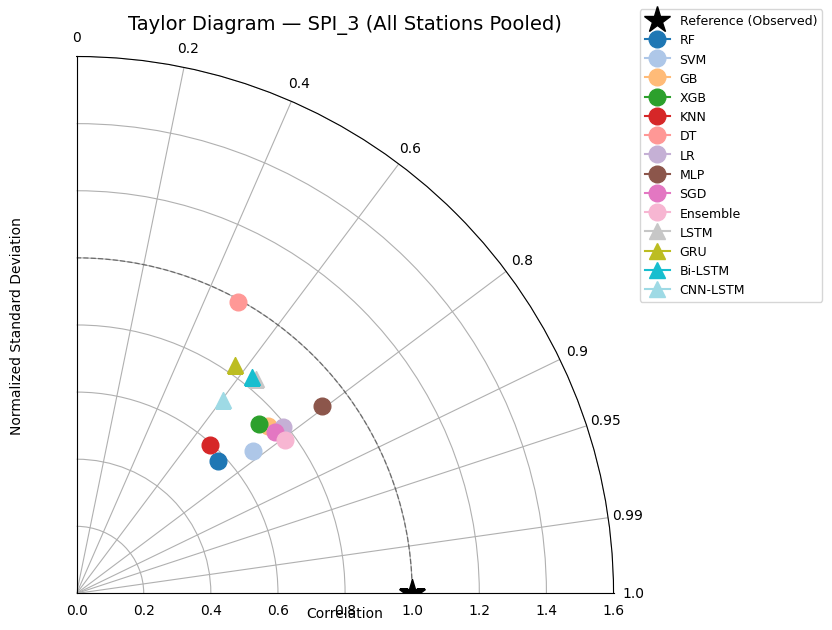

In [ ]:
def taylor_diagram_stats(y_true, y_pred):
    """Compute normalized std and correlation for Taylor diagram."""
    std_true = np.std(y_true)
    std_pred = np.std(y_pred)
    corr = np.corrcoef(y_true, y_pred)[0, 1]
    return std_pred / std_true, corr  # normalized std ratio, correlation

def plot_taylor_diagram(pooled_predictions, title="Taylor Diagram"):
    fig = plt.figure(figsize=(9, 9))
    ax = fig.add_subplot(111, polar=True)

    ax.set_thetamin(0)
    ax.set_thetamax(90)
    ax.set_theta_zero_location('E')
    ax.set_theta_direction(1)

    corr_ticks = [0, 0.2, 0.4, 0.6, 0.8, 0.9, 0.95, 0.99, 1.0]
    ax.set_xticks(np.arccos(corr_ticks))
    ax.set_xticklabels([str(c) for c in corr_ticks])
    ax.set_xlabel('Correlation')

    max_std = 1.6
    ax.set_ylim(0, max_std)
    ax.set_ylabel('Normalized Standard Deviation', labelpad=30)

    # Reference point (observed): std_ratio=1, corr=1
    ax.plot(0, 1, 'k*', markersize=20, label='Reference (Observed)')

    # Reference std circle
    theta_range = np.linspace(0, np.pi/2, 100)
    ax.plot(theta_range, np.ones_like(theta_range), 'k--', alpha=0.4, linewidth=1)

    colors = plt.cm.tab20(np.linspace(0, 1, len(pooled_predictions)))
    for (name, data), color in zip(pooled_predictions.items(), colors):
        std_ratio, corr = taylor_diagram_stats(data['y_true'], data['y_pred'])
        theta = np.arccos(np.clip(corr, -1, 1))
        marker = 'o' if name in ml_builders else '^'
        ax.plot(theta, std_ratio, marker=marker, markersize=12, color=color, label=name)

    ax.legend(loc='upper right', bbox_to_anchor=(1.4, 1.1), fontsize=9)
    plt.title(title, fontsize=14, pad=20)
    plt.tight_layout()
    plt.savefig("taylor_diagram_all_models.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_taylor_diagram(pooled_predictions, title=f"Taylor Diagram — {TARGET_INDEX} (All Stations Pooled)")

**Identify Best Overall Model & Save Final Comparison Summary**

In [ ]:
taylor_stats_table = []
for name, data in pooled_predictions.items():
    std_ratio, corr = taylor_diagram_stats(data['y_true'], data['y_pred'])
    taylor_stats_table.append({
        'Model': name,
        'Type': 'ML' if name in ml_builders else 'DL',
        'Correlation': round(corr, 4),
        'Std_Ratio': round(std_ratio, 4),
        'Distance_from_Ideal': round(np.sqrt((1-corr)**2 + (1-std_ratio)**2), 4)
    })

taylor_df = pd.DataFrame(taylor_stats_table).sort_values('Distance_from_Ideal')
print("=== Taylor Diagram Statistics (sorted by closeness to ideal) ===")
print(taylor_df)
taylor_df.to_csv("taylor_diagram_statistics.csv", index=False)

best_model = taylor_df.iloc[0]['Model']
print(f"\n🏆 Best overall model (closest to ideal reference point): {best_model}")

print(f"\n=== R² Ranking (Testing Phase) ===")
print(master_summary['R2'].sort_values(ascending=False))

=== Taylor Diagram Statistics (sorted by closeness to ideal) ===
       Model Type  Correlation  Std_Ratio  Distance_from_Ideal
7        MLP   ML       0.7949     0.9198               0.2202
9   Ensemble   ML       0.8053     0.7711               0.3005
6         LR   ML       0.7773     0.7897               0.3063
8        SGD   ML       0.7747     0.7626               0.3273
2         GB   ML       0.7522     0.7590               0.3457
3        XGB   ML       0.7336     0.7421               0.3708
1        SVM   ML       0.7782     0.6763               0.3924
10      LSTM   DL       0.6404     0.8325               0.3967
12   Bi-LSTM   DL       0.6290     0.8299               0.4081
11       GRU   DL       0.5702     0.8270               0.4634
13  CNN-LSTM   DL       0.6042     0.7239               0.4826
0         RF   ML       0.7302     0.5771               0.5016
5         DT   ML       0.4830     0.9929               0.5171
4        KNN   ML       0.6675     0.5957            

**Global Font Size Configuration for Publication-Quality Plots**

In [ ]:
"""**Global Font Size Configuration for Publication-Quality Plots**"""

import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 48,
    'axes.titleweight': 'bold',
    'axes.labelsize': 42,
    'axes.labelweight': 'bold',
    'xtick.labelsize': 36,
    'ytick.labelsize': 36,
    'legend.fontsize': 36,
    'figure.titlesize': 54,
    'figure.titleweight': 'bold'
})
print("✅ Global font sizes updated for publication-quality plots (3x)")

✅ Global font sizes updated for publication-quality plots (3x)


**Time-Series Line Plots — SPI/SPEI/ZSI per Station (One Grid per Scale)**

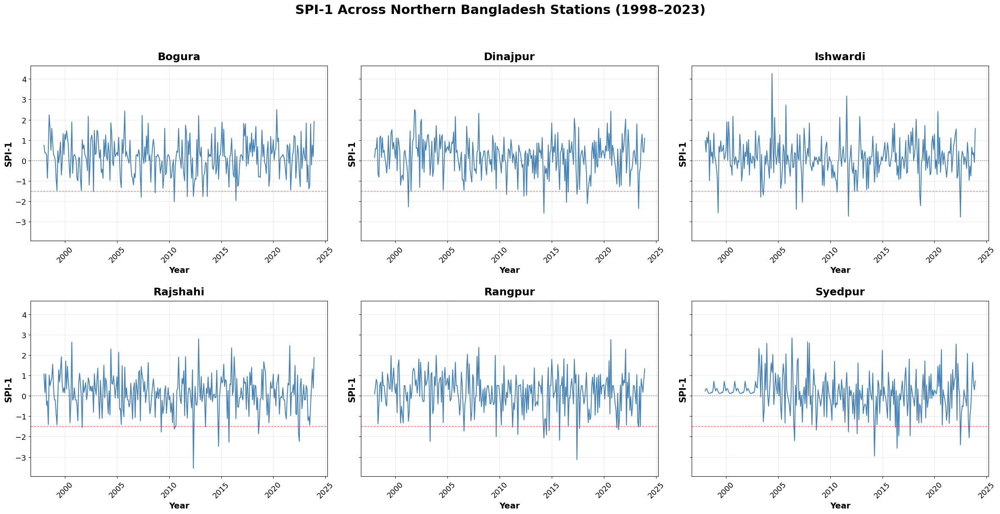

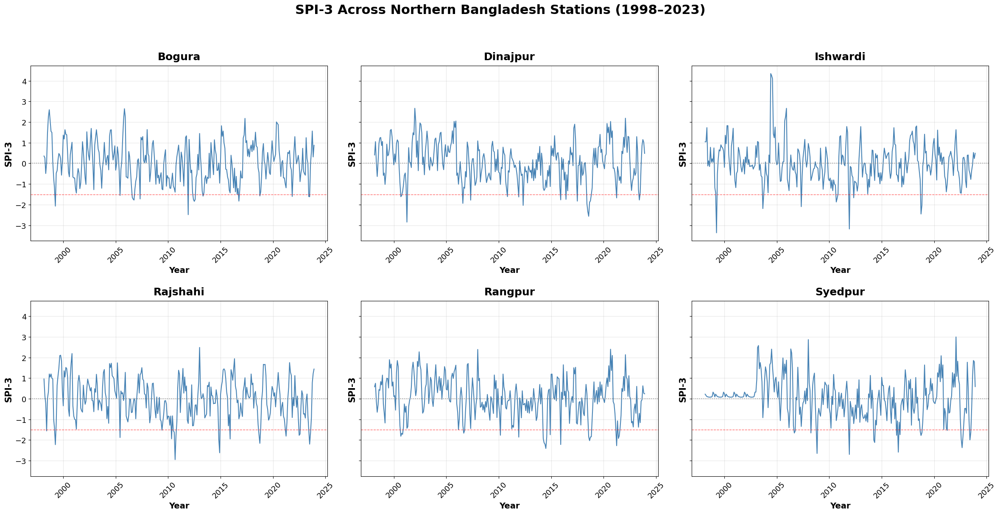

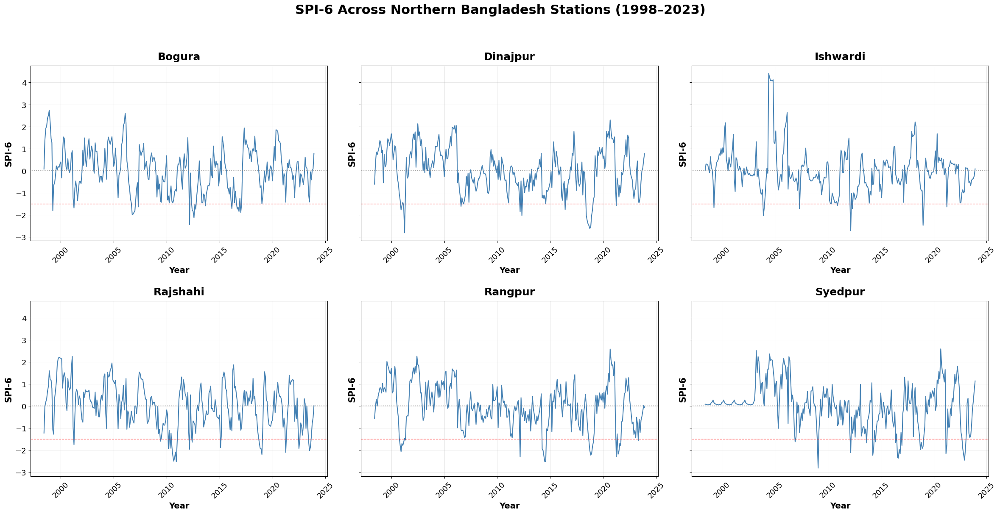

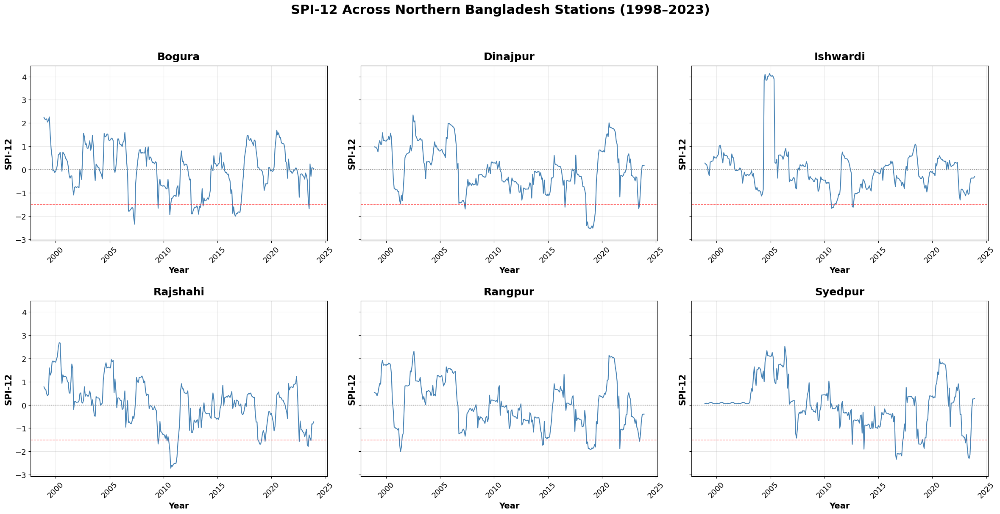

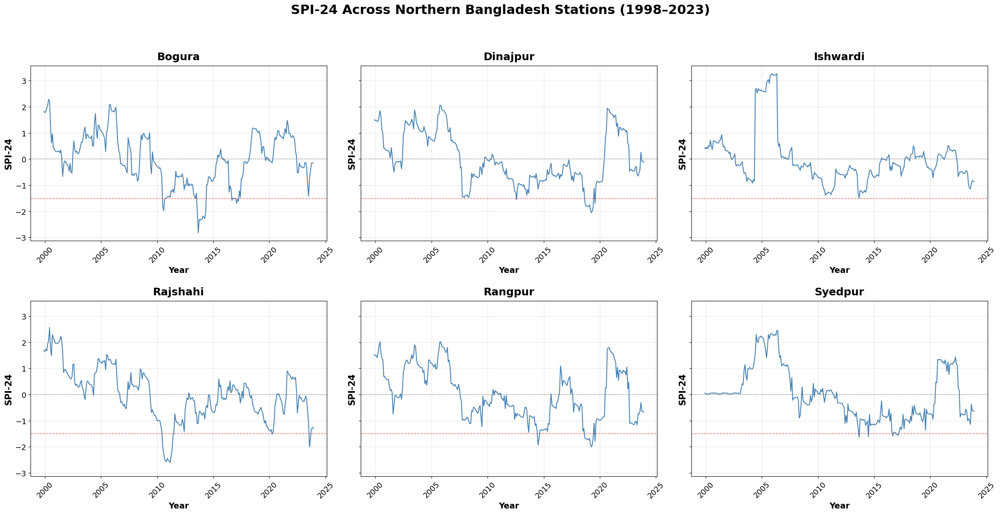

In [ ]:
def plot_index_grid(df, index_prefix, scale, locations):
    """Plot SPI/SPEI/ZSI line charts for one scale, across all stations in a grid."""
    col = f'{index_prefix}_{scale}'
    fig, axes = plt.subplots(2, 3, figsize=(24, 12), sharey=True)
    axes = axes.flatten()

    for i, loc in enumerate(locations):
        sub = df[df['Location'] == loc].sort_values('Date')
        ax = axes[i]
        ax.plot(sub['Date'], sub[col], color='steelblue', linewidth=1.5)
        ax.axhline(0, color='gray', linestyle=':', linewidth=1.2)
        ax.axhline(-1.5, color='red', linestyle='--', linewidth=1, alpha=0.6)

        ax.set_title(loc, fontsize=18, fontweight='bold', pad=10)
        ax.set_ylabel(f'{index_prefix}-{scale}', fontsize=15, fontweight='bold')
        ax.set_xlabel('Year', fontsize=14, fontweight='bold')

        ax.tick_params(axis='both', labelsize=13)
        ax.tick_params(axis='x', rotation=45)

        ax.xaxis.set_major_locator(plt.matplotlib.dates.YearLocator(5))
        ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%Y'))

        ax.grid(alpha=0.3, linewidth=0.8)

    plt.suptitle(f'{index_prefix}-{scale} Across Northern Bangladesh Stations (1998–2023)',
                 fontsize=22, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(f"{index_prefix}_{scale}_station_grid.png", dpi=200, bbox_inches='tight')
    plt.show()

for scale in [1, 3, 6, 12, 24]:
    plot_index_grid(df_idx, 'SPI', scale, locations_list)

**Same Grid for SPEI**

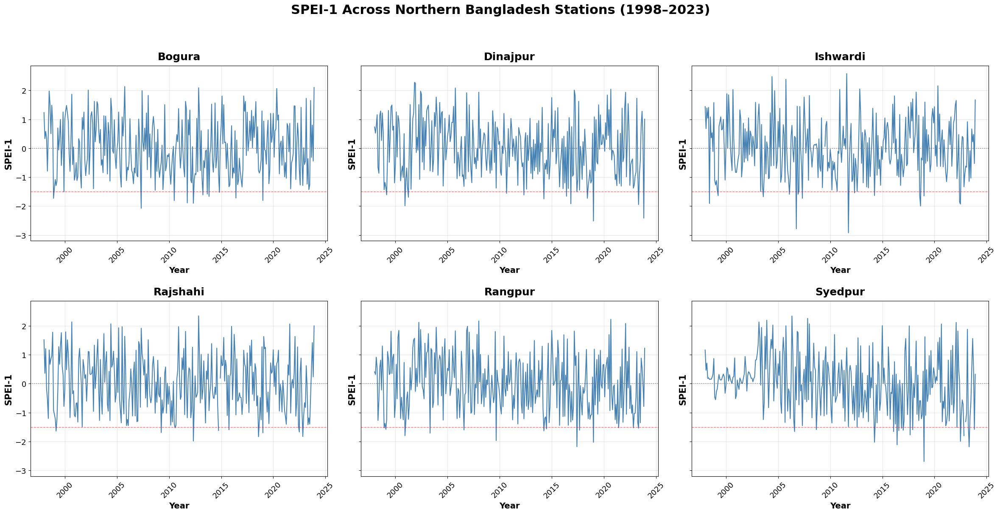

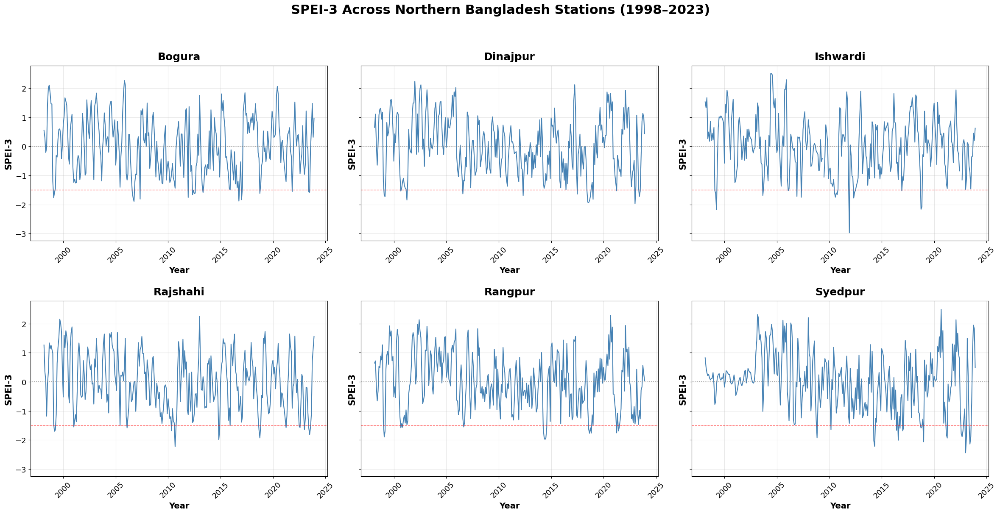

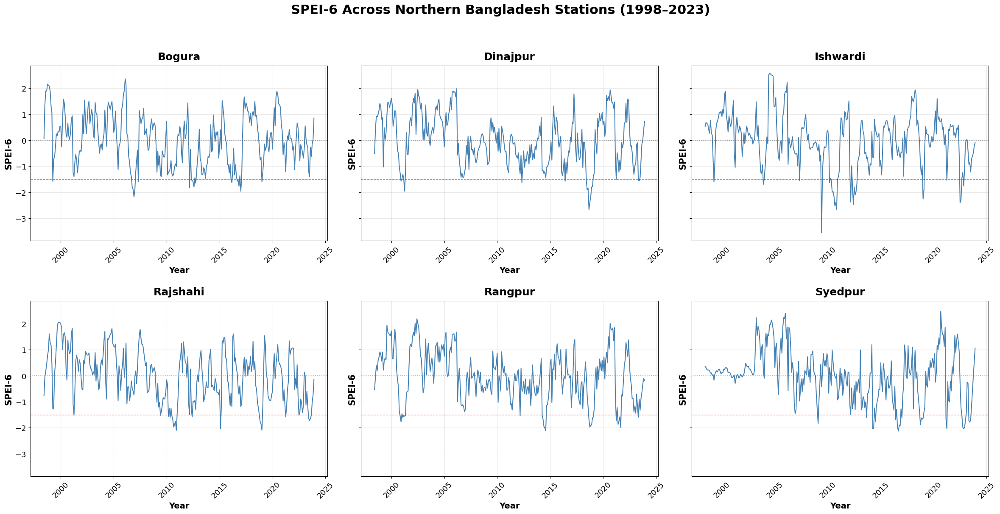

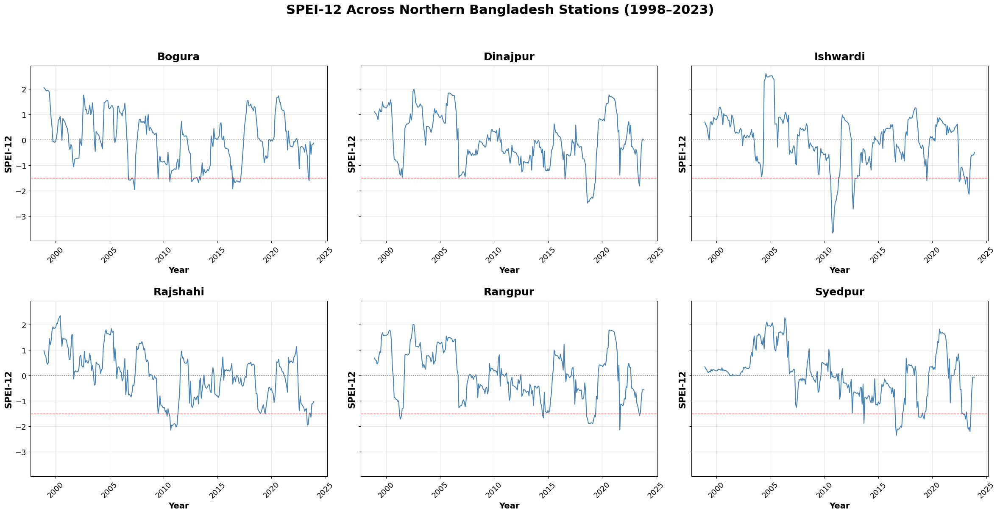

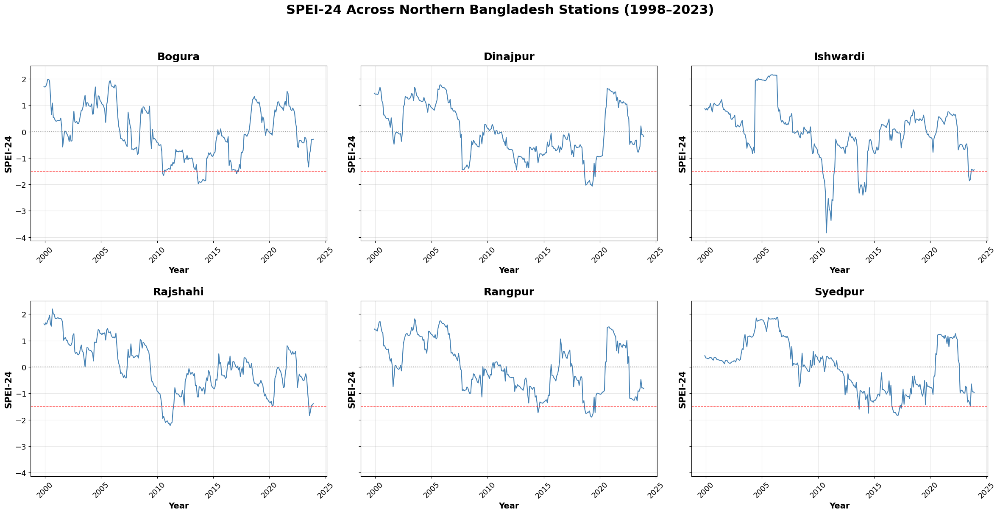

In [ ]:
for scale in [1, 3, 6, 12, 24]:
    plot_index_grid(df_idx, 'SPEI', scale, locations_list)

**Drought Frequency Table (Counts per Station, per Index, per Scale)**

In [ ]:
drought_categories = ['No drought', 'Mild drought', 'Moderate drought', 'Severe drought', 'Extreme drought']
index_prefixes = ['SPI', 'SPEI', 'ZSI']
scales = [1, 3, 6, 12, 24]

freq_records = []
for loc in locations_list:
    sub = df_idx[df_idx['Location'] == loc]
    for prefix in index_prefixes:
        for scale in scales:
            class_col = f'{prefix}_{scale}_class'
            if class_col not in sub.columns:
                continue
            counts = sub[class_col].value_counts()
            record = {'Location': loc, 'Index': prefix, 'Scale': scale}
            for cat in drought_categories:
                record[cat] = counts.get(cat, 0)
            freq_records.append(record)

drought_freq_table = pd.DataFrame(freq_records)
drought_freq_table.to_csv("drought_frequency_table.csv", index=False)

print("✅ Saved: drought_frequency_table.csv")
print("\nExample — SPI frequency table (all scales, all stations):")
drought_freq_table[drought_freq_table['Index']=='SPI']

✅ Saved: drought_frequency_table.csv

Example — SPI frequency table (all scales, all stations):


,Location,Index,Scale,No drought,Mild drought,Moderate drought,Severe drought,Extreme drought
0,Bogura,SPI,1,189,97,17,8,1
1,Bogura,SPI,3,161,102,30,15,2
2,Bogura,SPI,6,159,93,35,18,2
3,Bogura,SPI,12,155,92,21,30,3
4,Bogura,SPI,24,138,105,23,13,10
15,Dinajpur,SPI,1,201,80,20,6,5
16,Dinajpur,SPI,3,157,110,24,15,4
17,Dinajpur,SPI,6,151,107,30,10,9
18,Dinajpur,SPI,12,136,123,27,5,10
19,Dinajpur,SPI,24,115,138,24,11,1


**Bar Chart — Drought Category Frequency by Station (SPI-3 example)**

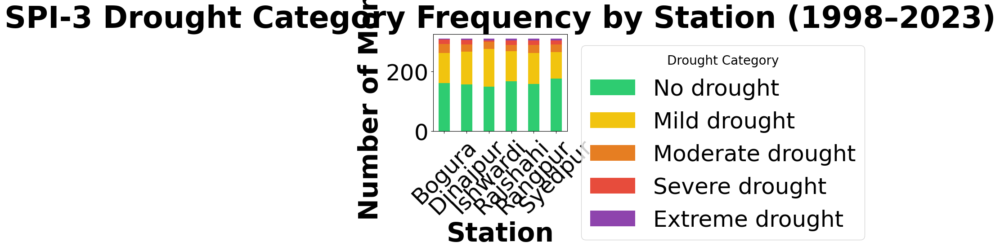

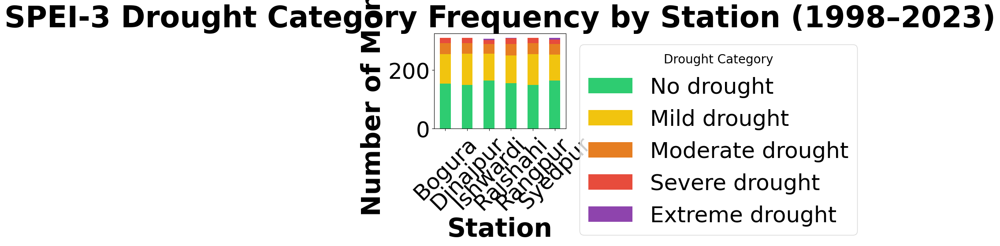

In [ ]:
def plot_drought_frequency_bars(freq_table, index_prefix, scale):
    sub = freq_table[(freq_table['Index']==index_prefix) & (freq_table['Scale']==scale)].set_index('Location')
    sub = sub[drought_categories]

    sub.plot(kind='bar', stacked=True, figsize=(12,6),
              color=['#2ecc71','#f1c40f','#e67e22','#e74c3c','#8e44ad'])
    plt.title(f'{index_prefix}-{scale} Drought Category Frequency by Station (1998–2023)')
    plt.ylabel('Number of Months')
    plt.xlabel('Station')
    plt.xticks(rotation=45)
    plt.legend(title='Drought Category', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig(f"{index_prefix}_{scale}_frequency_bars.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_drought_frequency_bars(drought_freq_table, 'SPI', 3)
plot_drought_frequency_bars(drought_freq_table, 'SPEI', 3)

**Decade-wise Drought Comparison (1998–2006, 2007–2015, 2016–2023)**

In [ ]:
def assign_period(year):
    if 1998 <= year <= 2006:
        return '1998-2006'
    elif 2007 <= year <= 2015:
        return '2007-2015'
    elif 2016 <= year <= 2023:
        return '2016-2023'
    return None

df_idx['Period'] = df_idx['Year'].apply(assign_period)

decade_records = []
for loc in locations_list:
    for period in ['1998-2006', '2007-2015', '2016-2023']:
        sub = df_idx[(df_idx['Location']==loc) & (df_idx['Period']==period)]
        for prefix in ['SPI', 'SPEI']:
            for scale in [3, 6, 12, 24]:
                class_col = f'{prefix}_{scale}_class'
                if class_col not in sub.columns:
                    continue
                counts = sub[class_col].value_counts()
                record = {'Location': loc, 'Period': period, 'Index': prefix, 'Scale': scale}
                for cat in drought_categories:
                    record[cat] = counts.get(cat, 0)
                decade_records.append(record)

decade_freq_table = pd.DataFrame(decade_records)
decade_freq_table.to_csv("decade_drought_frequency_table.csv", index=False)
print("✅ Saved: decade_drought_frequency_table.csv")

decade_freq_table[(decade_freq_table['Index']=='SPI') & (decade_freq_table['Scale']==12)]

✅ Saved: decade_drought_frequency_table.csv


,Location,Period,Index,Scale,No drought,Mild drought,Moderate drought,Severe drought,Extreme drought
2,Bogura,1998-2006,SPI,12,68,25,1,3,0
10,Bogura,2007-2015,SPI,12,45,28,16,17,2
18,Bogura,2016-2023,SPI,12,42,39,4,10,1
26,Dinajpur,1998-2006,SPI,12,80,10,7,0,0
34,Dinajpur,2007-2015,SPI,12,18,73,16,1,0
42,Dinajpur,2016-2023,SPI,12,38,40,4,4,10
50,Ishwardi,1998-2006,SPI,12,61,34,2,0,0
58,Ishwardi,2007-2015,SPI,12,28,62,12,6,0
66,Ishwardi,2016-2023,SPI,12,42,48,6,0,0
74,Rajshahi,1998-2006,SPI,12,83,14,0,0,0


**Decade Comparison Chart — Severe+Extreme Drought Trend (SPI-12 example)**

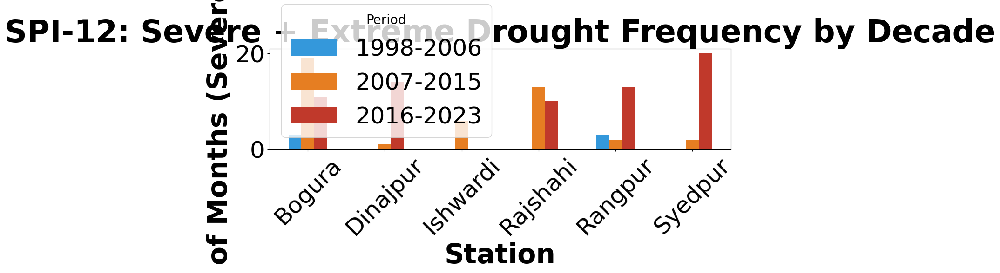

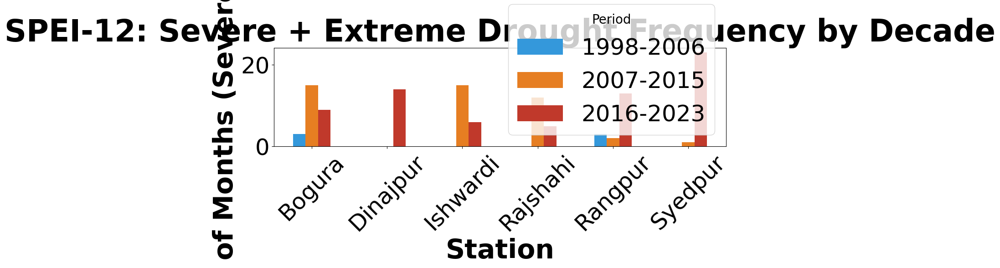

In [ ]:
def plot_decade_trend(decade_table, index_prefix, scale, severity=['Severe drought','Extreme drought']):
    sub = decade_table[(decade_table['Index']==index_prefix) & (decade_table['Scale']==scale)].copy()
    sub['Severe_Extreme'] = sub[severity].sum(axis=1)
    pivot = sub.pivot(index='Location', columns='Period', values='Severe_Extreme')

    pivot.plot(kind='bar', figsize=(12,6), color=['#3498db','#e67e22','#c0392b'])
    plt.title(f'{index_prefix}-{scale}: Severe + Extreme Drought Frequency by Decade')
    plt.ylabel('Number of Months (Severe + Extreme)')
    plt.xlabel('Station')
    plt.xticks(rotation=45)
    plt.legend(title='Period')
    plt.tight_layout()
    plt.savefig(f"{index_prefix}_{scale}_decade_trend.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_decade_trend(decade_freq_table, 'SPI', 12)
plot_decade_trend(decade_freq_table, 'SPEI', 12)

**Station Comparison Heatmap — % of Months in Drought (All Scales, SPI & SPEI)**

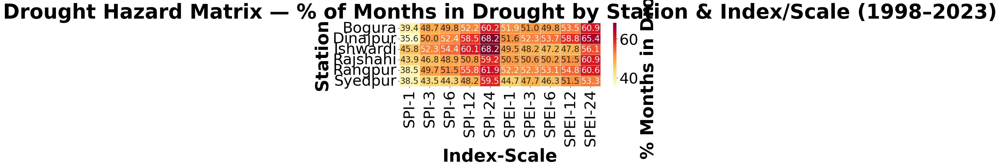

✅ Saved: drought_hazard_matrix.csv


In [ ]:
def compute_drought_percentage(df, index_prefix, scale):
    """% of months classified as Mild/Moderate/Severe/Extreme (i.e., any drought) per station."""
    class_col = f'{index_prefix}_{scale}_class'
    pct = df.groupby('Location')[class_col].apply(
        lambda x: (x != 'No drought').sum() / x.notna().sum() * 100
    )
    return pct

heatmap_data = pd.DataFrame(index=locations_list)
for prefix in ['SPI', 'SPEI']:
    for scale in [1, 3, 6, 12, 24]:
        heatmap_data[f'{prefix}-{scale}'] = compute_drought_percentage(df_idx, prefix, scale)

plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data.round(1), annot=True, fmt='.1f', cmap='YlOrRd',
            cbar_kws={'label': '% Months in Drought'}, linewidths=0.5)
plt.title('Drought Hazard Matrix — % of Months in Drought by Station & Index/Scale (1998–2023)')
plt.xlabel('Index-Scale')
plt.ylabel('Station')
plt.tight_layout()
plt.savefig("drought_hazard_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

heatmap_data.to_csv("drought_hazard_matrix.csv")
print("✅ Saved: drought_hazard_matrix.csv")

**Overall Drought Hotspot Ranking (Replaces GIS "Hotspot" Identification)**

=== Drought Hotspot Ranking (avg % months in drought, across all indices/scales) ===
Dinajpur    54.65
Rangpur     53.03
Ishwardi    52.96
Bogura      51.75
Rajshahi    51.32
Syedpur     47.75
dtype: float64


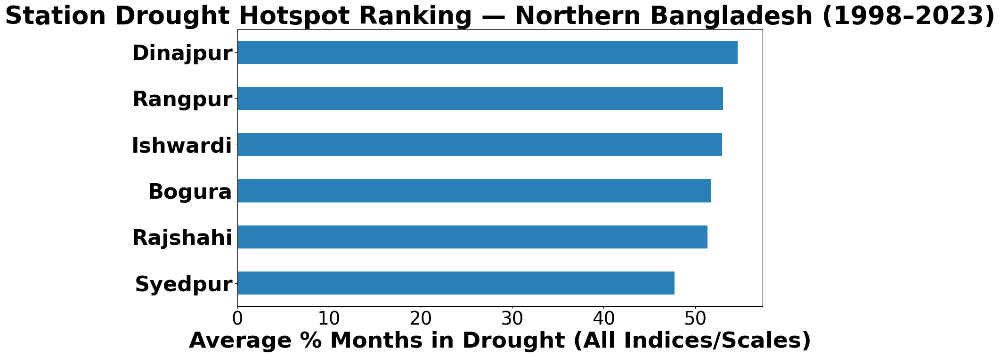

In [ ]:
"""**Overall Drought Hotspot Ranking (Replaces GIS "Hotspot" Identification)**"""

hotspot_ranking = heatmap_data.mean(axis=1).sort_values(ascending=False)
print("=== Drought Hotspot Ranking (avg % months in drought, across all indices/scales) ===")
print(hotspot_ranking.round(2))

plt.figure(figsize=(14, 8))
hotspot_ranking.plot(kind='barh', color='#2980b9')  # blue instead of crimson
plt.xlabel('Average % Months in Drought (All Indices/Scales)', fontsize=34, fontweight='bold')
plt.title('Station Drought Hotspot Ranking — Northern Bangladesh (1998–2023)', fontsize=38, fontweight='bold')
plt.xticks(fontsize=28)
plt.yticks(fontsize=32, fontweight='bold')   # station names, enlarged
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("drought_hotspot_ranking.png", dpi=150, bbox_inches='tight')
plt.show()

**Extract Forecast Period & Plot SPI/SPEI Trends per Station Marge Item**

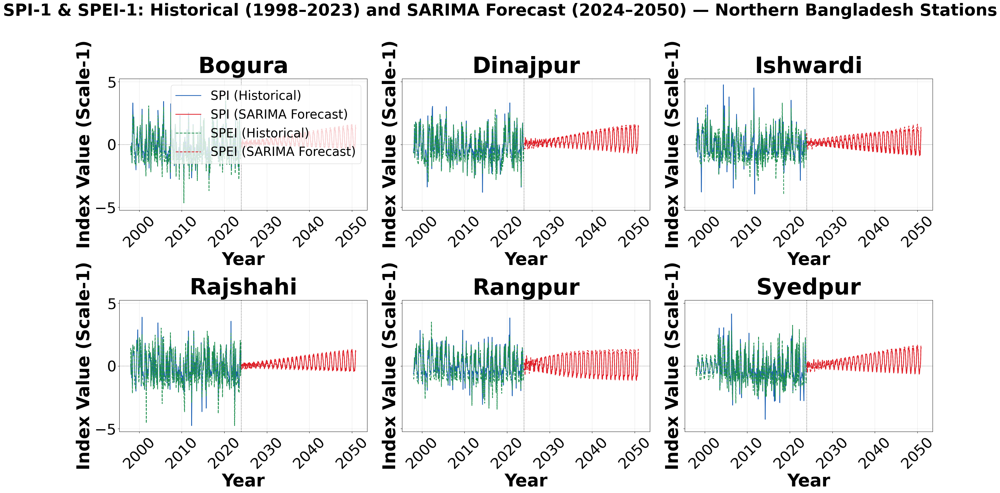

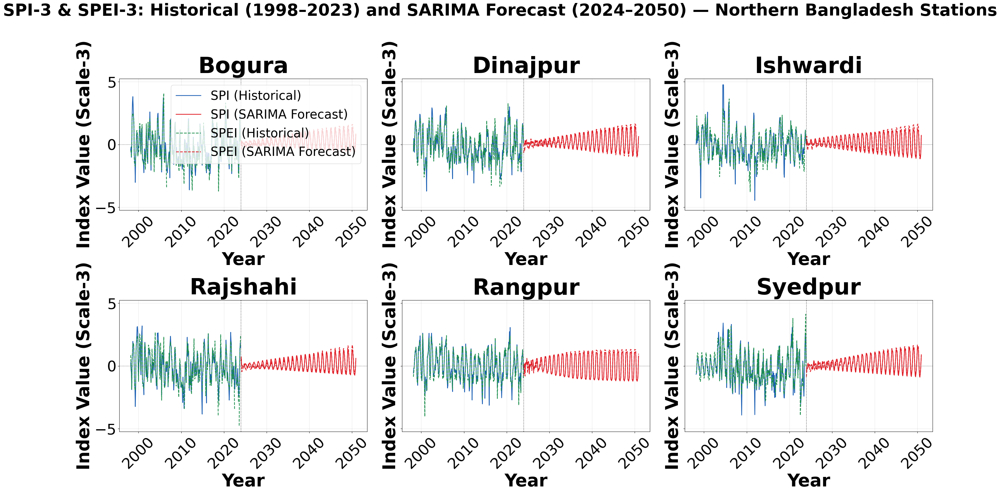

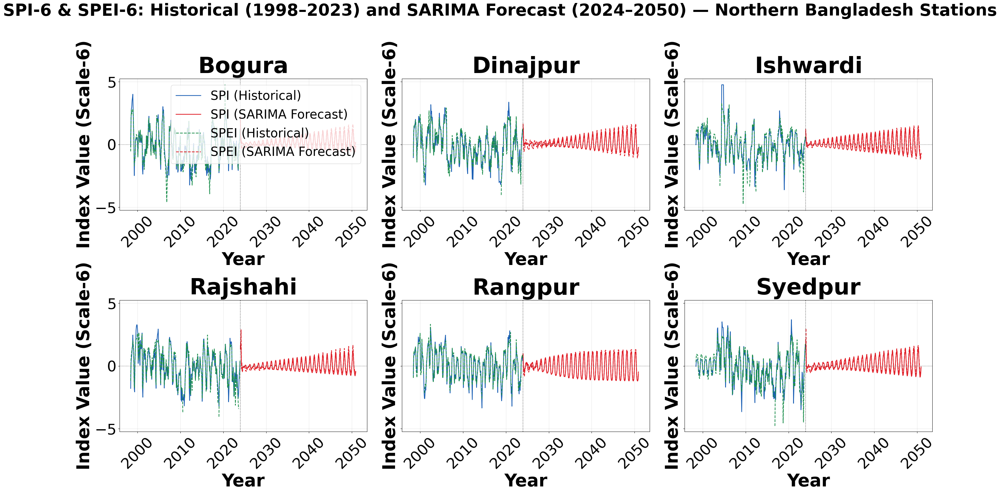

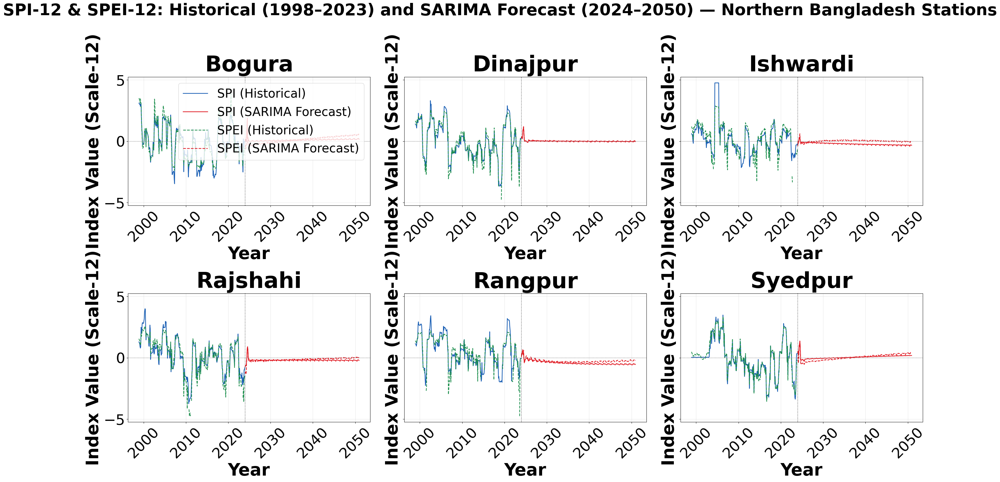

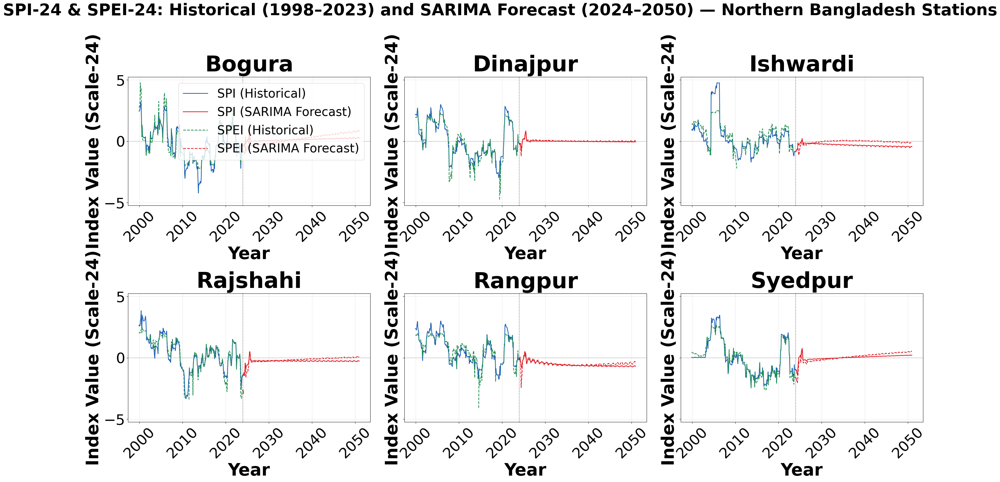

In [ ]:
"""**Combined SPI + SPEI Time-Series — Historical (1998–2023) + SARIMA Forecast (2024–2050), per Station**"""

def plot_combined_index_grid(df, scale, locations, hist_cutoff=forecast_start):
    """Merge SPI and SPEI onto one panel per station, full 1998-2050 span.
    Line style encodes the index (SPI=solid, SPEI=dashed); color encodes
    historical vs. SARIMA-forecast (navy/green -> red at the cutover)."""
    spi_col = f'SPI_{scale}'
    spei_col = f'SPEI_{scale}'
    fig, axes = plt.subplots(2, 3, figsize=(30, 16), sharey=True)
    axes = axes.flatten()

    for i, loc in enumerate(locations):
        sub = df[df['Location'] == loc].sort_values('Date')
        hist = sub[sub['Date'] < hist_cutoff]
        fut  = sub[sub['Date'] >= hist_cutoff]
        ax = axes[i]

        # SPI - solid line
        ax.plot(hist['Date'], hist[spi_col], color='#1a5fb4', linewidth=1.8,
                 linestyle='-', label='SPI (Historical)')
        ax.plot(fut['Date'], fut[spi_col], color='#e01b24', linewidth=1.8,
                 linestyle='-', label='SPI (SARIMA Forecast)')

        # SPEI - dashed line
        ax.plot(hist['Date'], hist[spei_col], color='#1e8f4e', linewidth=1.8,
                 linestyle='--', label='SPEI (Historical)')
        ax.plot(fut['Date'], fut[spei_col], color='#e01b24', linewidth=1.8,
                 linestyle='--', label='SPEI (SARIMA Forecast)')

        ax.axhline(0, color='gray', linestyle=':', linewidth=1.2)
        ax.axvline(hist_cutoff, color='black', linestyle=':', linewidth=1.4, alpha=0.7)

        # --- enlarged labels (3x) ---
        ax.set_title(loc, fontsize=54, fontweight='bold', pad=14)
        ax.set_ylabel(f'Index Value (Scale-{scale})', fontsize=42, fontweight='bold')
        ax.set_xlabel('Year', fontsize=42, fontweight='bold')
        ax.tick_params(axis='both', labelsize=36)
        ax.tick_params(axis='x', rotation=45)

        ax.xaxis.set_major_locator(plt.matplotlib.dates.YearLocator(10))
        ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%Y'))
        ax.grid(alpha=0.3, linewidth=0.8)

        if i == 0:
            ax.legend(fontsize=30, loc='upper right', frameon=True)

    plt.suptitle(f'SPI-{scale} & SPEI-{scale}: Historical (1998–2023) and SARIMA Forecast (2024–2050) '
                 f'— Northern Bangladesh Stations', fontsize=40, fontweight='bold', y=1.04)
    plt.tight_layout()
    plt.savefig(f"combined_SPI_SPEI_{scale}_station_grid.png", dpi=200, bbox_inches='tight')
    plt.show()

for scale in [1, 3, 6, 12, 24]:
    plot_combined_index_grid(combined_df, scale, locations_list)

**Same Grid for SPEI (Forecast Period)**

In [ ]:
#for scale in [1, 3, 6, 12, 24]:
#    plot_forecast_grid(combined_df, 'SPEI', scale, locations_list)

**Drought Frequency Table — Forecast Period Only (2024–2050)**

In [ ]:
forecast_freq_records = []
for loc in locations_list:
    sub = forecast_only[forecast_only['Location'] == loc]
    for prefix in ['SPI', 'SPEI']:
        for scale in [1, 3, 6, 12, 24]:
            class_col = f'{prefix}_{scale}_class'
            if class_col not in sub.columns:
                continue
            counts = sub[class_col].value_counts()
            record = {'Location': loc, 'Index': prefix, 'Scale': scale}
            for cat in drought_categories:
                record[cat] = counts.get(cat, 0)
            forecast_freq_records.append(record)

forecast_freq_table = pd.DataFrame(forecast_freq_records)
forecast_freq_table.to_csv("forecast_drought_frequency_table.csv", index=False)

print("✅ Saved: forecast_drought_frequency_table.csv")
forecast_freq_table[(forecast_freq_table['Index']=='SPI') & (forecast_freq_table['Scale']==12)]

NameError: name 'forecast_only' is not defined

**Historical (2016–2023) vs Forecast (2024–2050) Comparison**

In [ ]:
def compute_period_drought_pct(df, date_start, date_end, index_prefix, scale):
    """% of months in drought (any severity) within a date range, per station."""
    class_col = f'{index_prefix}_{scale}_class'
    sub = df[(df['Date'] >= date_start) & (df['Date'] <= date_end)]
    pct = sub.groupby('Location')[class_col].apply(
        lambda x: (x != 'No drought').sum() / x.notna().sum() * 100
    )
    return pct

comparison_records = []
for prefix in ['SPI', 'SPEI']:
    for scale in [3, 6, 12, 24]:
        recent_hist_pct = compute_period_drought_pct(combined_df, '2016-01-01', '2023-12-31', prefix, scale)
        forecast_pct = compute_period_drought_pct(combined_df, '2024-01-01', '2050-12-31', prefix, scale)
        for loc in locations_list:
            comparison_records.append({
                'Location': loc, 'Index': prefix, 'Scale': scale,
                'Recent_Historical_2016_2023_%': round(recent_hist_pct.get(loc, np.nan), 2),
                'Forecast_2024_2050_%': round(forecast_pct.get(loc, np.nan), 2)
            })

hist_vs_forecast = pd.DataFrame(comparison_records)
hist_vs_forecast['Change_%'] = (hist_vs_forecast['Forecast_2024_2050_%'] -
                                  hist_vs_forecast['Recent_Historical_2016_2023_%']).round(2)
hist_vs_forecast.to_csv("historical_vs_forecast_comparison.csv", index=False)

print("✅ Saved: historical_vs_forecast_comparison.csv")
hist_vs_forecast[(hist_vs_forecast['Index']=='SPI') & (hist_vs_forecast['Scale']==12)]

**Bar Chart — Recent Historical vs Forecast Drought % (SPI-12 example)**

In [ ]:
def plot_hist_vs_forecast(comp_table, index_prefix, scale):
    sub = comp_table[(comp_table['Index']==index_prefix) & (comp_table['Scale']==scale)].set_index('Location')

    x = np.arange(len(sub))
    width = 0.35
    fig, ax = plt.subplots(figsize=(12,6))
    ax.bar(x - width/2, sub['Recent_Historical_2016_2023_%'], width, label='2016–2023 (Historical)', color='steelblue')
    ax.bar(x + width/2, sub['Forecast_2024_2050_%'], width, label='2024–2050 (Forecast)', color='crimson')

    ax.set_xticks(x)
    ax.set_xticklabels(sub.index, rotation=45)
    ax.set_ylabel('% Months in Drought')
    ax.set_title(f'{index_prefix}-{scale}: Recent Historical vs Forecast Drought Frequency')
    ax.legend()
    plt.tight_layout()
    plt.savefig(f"hist_vs_forecast_{index_prefix}_{scale}.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_hist_vs_forecast(hist_vs_forecast, 'SPI', 12)
plot_hist_vs_forecast(hist_vs_forecast, 'SPEI', 12)

**Forecast-Period Hazard Heatmap**

In [ ]:
forecast_heatmap_data = pd.DataFrame(index=locations_list)
for prefix in ['SPI', 'SPEI']:
    for scale in [1, 3, 6, 12, 24]:
        forecast_heatmap_data[f'{prefix}-{scale}'] = compute_drought_percentage(forecast_only, prefix, scale)

plt.figure(figsize=(12, 6))
sns.heatmap(forecast_heatmap_data.round(1), annot=True, fmt='.1f', cmap='YlOrRd',
            cbar_kws={'label': '% Months in Drought'}, linewidths=0.5)
plt.title('Forecast Drought Hazard Matrix — % of Months in Drought by Station (2024–2050)')
plt.xlabel('Index-Scale')
plt.ylabel('Station')
plt.tight_layout()
plt.savefig("forecast_drought_hazard_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

forecast_heatmap_data.to_csv("forecast_drought_hazard_matrix.csv")
print("✅ Saved: forecast_drought_hazard_matrix.csv")

**ARIMA vs SARIMA — Do They Project Different Future Drought Patterns?**

In [ ]:
# Build ARIMA-based future dataset (parallel to the SARIMA-based combined_df from Step 4)
future_wide_arima = forecast_df.pivot_table(index=['Location','Date'], columns='Variable',
                                              values='ARIMA_forecast').reset_index()
future_wide_arima['Year'] = future_wide_arima['Date'].dt.year
future_wide_arima['Month'] = future_wide_arima['Date'].dt.month

future_wide_arima['PET'] = future_wide_arima.apply(
    lambda row: hargreaves_pet(row['Max temp (°C)'], row['Min temp (°C)'],
                                 station_lat[row['Location']], row['Month'], row['Year']),
    axis=1
)
future_wide_arima['WaterBalance'] = future_wide_arima['Rainfall (mm)'] - future_wide_arima['PET']

combined_df_arima = pd.concat([df_idx[shared_cols], future_wide_arima[shared_cols]], ignore_index=True)
combined_df_arima = combined_df_arima.sort_values(['Location','Date']).reset_index(drop=True)

for loc in combined_df_arima['Location'].unique():
    mask = combined_df_arima['Location'] == loc
    sub = combined_df_arima.loc[mask]
    for scale in [1, 3, 6, 12, 24]:
        combined_df_arima.loc[mask, f'SPI_{scale}'] = compute_spi(sub['Rainfall (mm)'], sub['Date'], scale)
        combined_df_arima.loc[mask, f'SPEI_{scale}'] = compute_spei(sub['WaterBalance'], sub['Date'], scale)

for scale in [1, 3, 6, 12, 24]:
    for prefix in ['SPI', 'SPEI']:
        combined_df_arima[f'{prefix}_{scale}_class'] = combined_df_arima[f'{prefix}_{scale}'].apply(classify_drought)

forecast_only_arima = combined_df_arima[combined_df_arima['Date'] >= forecast_start].copy()

# Compare % drought months: ARIMA-based vs SARIMA-based forecast
arima_vs_sarima = []
for prefix in ['SPI', 'SPEI']:
    for scale in [3, 6, 12, 24]:
        arima_pct = compute_drought_percentage(forecast_only_arima, prefix, scale)
        sarima_pct = compute_drought_percentage(forecast_only, prefix, scale)
        for loc in locations_list:
            arima_vs_sarima.append({
                'Location': loc, 'Index': prefix, 'Scale': scale,
                'ARIMA_forecast_%': round(arima_pct.get(loc, np.nan), 2),
                'SARIMA_forecast_%': round(sarima_pct.get(loc, np.nan), 2)
            })

arima_vs_sarima_df = pd.DataFrame(arima_vs_sarima)
arima_vs_sarima_df['Difference'] = (arima_vs_sarima_df['SARIMA_forecast_%'] -
                                      arima_vs_sarima_df['ARIMA_forecast_%']).round(2)
arima_vs_sarima_df.to_csv("arima_vs_sarima_forecast_comparison.csv", index=False)

print("✅ Saved: arima_vs_sarima_forecast_comparison.csv")
print("\n=== ARIMA vs SARIMA Forecasted Drought % — SPI-12 ===")
print(arima_vs_sarima_df[(arima_vs_sarima_df['Index']=='SPI') & (arima_vs_sarima_df['Scale']==12)])

print(f"\nAverage absolute difference between ARIMA and SARIMA forecasts: "
      f"{arima_vs_sarima_df['Difference'].abs().mean():.2f} percentage points")

In [ ]:
import zipfile
import os
from google.colab import files

zip_name = 'drought_project_files_V2.zip'

with zipfile.ZipFile(zip_name, 'w') as zipf:
    for file in os.listdir('.'):
        if file.endswith('.png') or file.endswith('.csv'):
            zipf.write(file)
            print(f"Added to zip: {file}")

print("\nZipping complete! Downloading now...")
files.download(zip_name)